# Q3: 买多少？

Q2 我们从全市场中筛选出了 3 只 ETF：沪深300、纳指100、黄金。但关键问题还没回答：**每只各买多少？**

等分？各买三分之一？还是有更聪明的分法？

### 路线图

**选什么标的（Q2 ✓）→ 每个买多少（Q3）→ 什么时候买卖（Q4）→ 怎么验证有效（Q5）**

本章解决第二步。分两个小步回答：**最简单的分法 → 更聪明的分法**

铁律不变：**先猜后验，数据说了算。**

### 前置条件

- 已完成 Q2
- 已安装 open-xquant：`pip install open-xquant[yfinance]`

### 操作方式

和前面一样：阅读说明 → 打开对应 spec → 复制到 TRAE → 观察结果 → 回来看解读。

---

## Step 1: 最简单的回答——各买三分之一

三只 ETF，各买多少？最自然的想法：**平均分，公平合理，各买 1/3。** 这个答案好不好？我们跑一遍看看。

👉 **打开 `specs/spec-01-equal-weight.md`，复制到 TRAE。**

In [1]:
from oxq.core import Engine, Strategy
from oxq.data import YFinanceDownloader, LocalMarketDataProvider
from oxq.indicators import RollingVolatility
from oxq.portfolio.optimizers import EqualWeightOptimizer, RiskParityOptimizer, TopNRankingOptimizer
from oxq.rules import RebalanceFrequencyRule
from oxq.signals import Threshold
from oxq.trade import SimBroker
from oxq.universe import StaticUniverse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 设置中文显示
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'SimHei', 'STHeiti']
plt.rcParams['axes.unicode_minus'] = False

# 常量
OUTPUT_DIR = Path("outputs/q3-riskparity-btc")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SYMBOLS = ("510300.SS", "513100.SS", "518880.SS")
SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "518880.SS": "黄金ETF",
}
START = "2021-01-01"
today = pd.Timestamp.now().strftime("%Y-%m-%d")

# 下载数据
downloader = YFinanceDownloader()
for sym in SYMBOLS:
    downloader.download(sym, start=START, end=today)

# 加载数据
market = LocalMarketDataProvider()
mktdata = {}
for sym in SYMBOLS:
    mktdata[sym] = market.get_bars(sym, START, today).copy()

print("数据加载完成")
for sym in SYMBOLS:
    print(f"  {SYMBOL_NAMES[sym]}: {len(mktdata[sym])} 个交易日")

数据加载完成
  沪深300ETF: 1320 个交易日
  纳指100ETF: 1321 个交易日
  黄金ETF: 1320 个交易日


In [2]:
# 构建投资宇宙
universe = StaticUniverse(symbols=SYMBOLS, name="global-macro-etf")

# 等权策略回测
signal_ew = Threshold()

strategy_ew = Strategy(
    name="equal-weight",
    universe=universe,
    signals={"active": (signal_ew, {"column": "close", "threshold": 0, "relationship": "gt"})},
    portfolio=EqualWeightOptimizer(),
)

rules_ew = [RebalanceFrequencyRule(interval_days=10)]
result_ew = Engine().run(
    strategy_ew,
    market=LocalMarketDataProvider(),
    broker=SimBroker(),
    start=START,
    end=today,
    rules=rules_ew,
)

# 从回测结果提取等权权重
ew_weights_df = result_ew.weights_df()
sample_date = ew_weights_df.index[-1]
print(f"等权权重（{sample_date.strftime('%Y-%m-%d')}）：")
for sym in SYMBOLS:
    w = ew_weights_df.loc[sample_date, sym]
    print(f"  {SYMBOL_NAMES[sym]}: {w:.1%}")

# 10 万元换算
total_capital = 100_000
print(f"\n假如你有 {total_capital:,} 元：")
for sym in SYMBOLS:
    w = ew_weights_df.loc[sample_date, sym]
    amount = total_capital * w
    print(f"  {SYMBOL_NAMES[sym]}: {amount:,.0f} 元 (权重 {w:.1%})")

print("\n权重（Weight）就是\u201c这笔钱怎么分\u201d——每只标的分到总资金的百分之多少。")

等权权重（2026-06-18）：
  沪深300ETF: 33.3%
  纳指100ETF: 33.3%
  黄金ETF: 33.3%

假如你有 100,000 元：
  沪深300ETF: 33,333 元 (权重 33.3%)
  纳指100ETF: 33,333 元 (权重 33.3%)
  黄金ETF: 33,333 元 (权重 33.3%)

权重（Weight）就是“这笔钱怎么分”——每只标的分到总资金的百分之多少。


In [3]:
# 三只 ETF 单独持有的表现
single_metrics = {}
for sym in SYMBOLS:
    close = mktdata[sym]["close"]
    cum_return = close.iloc[-1] / close.iloc[0] - 1
    daily_ret = close.pct_change().dropna()
    annual_vol = daily_ret.std() * np.sqrt(252)
    cummax = close.cummax()
    max_dd = ((close - cummax) / cummax).min()
    single_metrics[sym] = {
        "cum_return": cum_return,
        "annual_vol": annual_vol,
        "max_dd": max_dd,
    }

# 对比表
ew_ret = result_ew.total_return()
ew_vol = result_ew.annualized_volatility()
ew_dd = result_ew.max_drawdown()

print("\n各标的表现对比")
print("=" * 60)
print(f"{'标的':<12} {'累计收益率':>10} {'年化波动率':>10} {'最大回撤':>10}")
print("-" * 60)
for sym in SYMBOLS:
    m = single_metrics[sym]
    print(f"{SYMBOL_NAMES[sym]:<12} {m['cum_return']:>10.2%} {m['annual_vol']:>10.2%} {m['max_dd']:>10.2%}")

print("-" * 60)
print(f"{'等权组合':<12} {ew_ret:>10.2%} {ew_vol:>10.2%} {ew_dd:>10.2%}")


各标的表现对比
标的                累计收益率      年化波动率       最大回撤
------------------------------------------------------------
沪深300ETF          4.65%     18.08%    -42.16%
纳指100ETF        161.48%     23.20%    -27.50%
黄金ETF           128.29%     17.05%    -28.55%
------------------------------------------------------------
等权组合             95.46%     13.30%    -16.47%


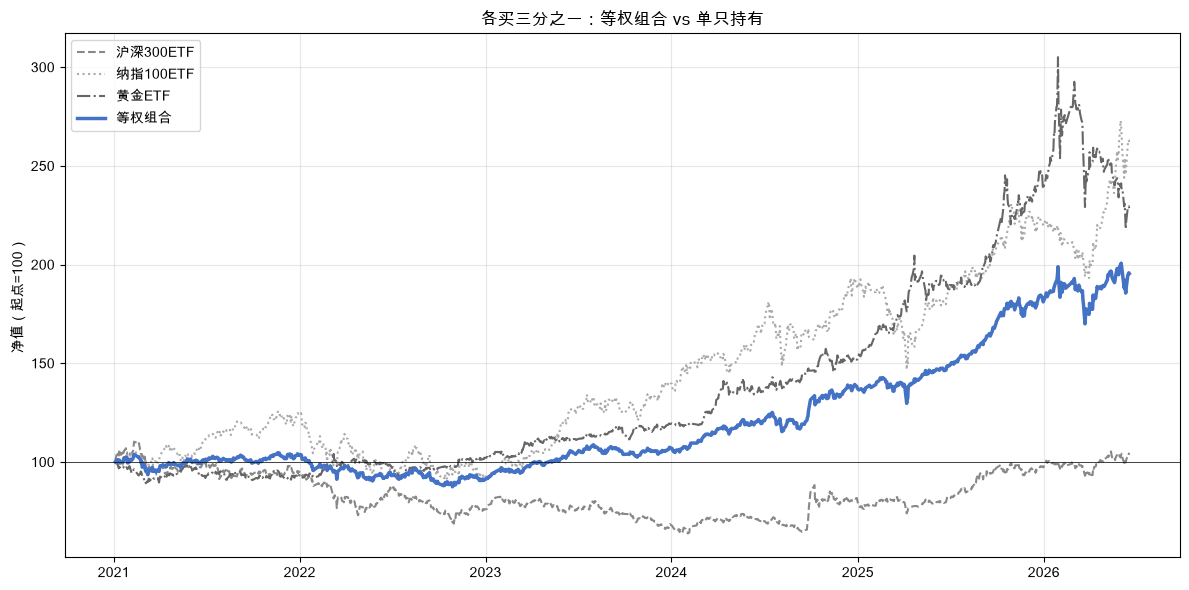


三只 ETF 各自的年化波动率从 17.05% 到 23.20%，差了 1.4 倍。
但等权信号说：不管你多颠簸，都买一样多的钱。
波动最大的纳指100ETF，虽然只花了 1/3 的钱，却主导了组合的涨跌。

有没有更聪明的分法——比如，波动大的少买点？


In [4]:
# 净值曲线对比图
fig, ax = plt.subplots(figsize=(12, 6))

# 取三个市场共同交易日（消除中美交易日历差异导致的净值跳变）
common_trading_days = mktdata[SYMBOLS[0]].index
for sym in SYMBOLS[1:]:
    common_trading_days = common_trading_days.intersection(mktdata[sym].index)

styles = [('--', '#888888'), (':', '#AAAAAA'), ('-.', '#666666')]
for i, sym in enumerate(SYMBOLS):
    close = mktdata[sym]["close"].reindex(common_trading_days)
    norm = close / close.iloc[0] * 100
    ls, color = styles[i]
    ax.plot(norm.index, norm.values, label=SYMBOL_NAMES[sym],
            linestyle=ls, color=color, linewidth=1.5)

# 等权组合净值
equity = pd.Series(dict(result_ew.equity_curve))
equity = equity.reindex(common_trading_days).dropna()
equity_norm = equity / equity.iloc[0] * 100
ax.plot(equity_norm.index, equity_norm.values, label='等权组合',
        color='#4472C4', linewidth=2.5)

ax.axhline(y=100, color='black', linestyle='-', linewidth=0.5)
ax.set_ylabel('净值（起点=100）')
ax.set_title('各买三分之一：等权组合 vs 单只持有')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01-equal-weight-nav.png", dpi=150, bbox_inches='tight')
plt.show()

# 分析
vols = [single_metrics[sym]['annual_vol'] for sym in SYMBOLS]
min_vol_name = SYMBOL_NAMES[SYMBOLS[np.argmin(vols)]]
max_vol_name = SYMBOL_NAMES[SYMBOLS[np.argmax(vols)]]
print(f"\n三只 ETF 各自的年化波动率从 {min(vols):.2%} 到 {max(vols):.2%}，差了 {max(vols)/min(vols):.1f} 倍。")
print(f"但等权信号说：不管你多颠簸，都买一样多的钱。")
print(f"波动最大的{max_vol_name}，虽然只花了 1/3 的钱，却主导了组合的涨跌。")
print(f"\n有没有更聪明的分法——比如，波动大的少买点？")

### Step 1 解读

等权组合的逻辑很简单：不管三只 ETF 各自什么脾气，一律平均分钱。

但数据告诉我们一个问题：**三只 ETF 的波动率差了好几倍。** 波动大的那只虽然只花了 1/3 的钱，却主导了整个组合的涨跌——平均分钱 ≠ 平均分影响。

那如果我们不平均分钱，而是**按波动来分**呢？波动大的少买点、波动小的多买点——组合是不是会更稳？

先猜后验。

---

## Step 2: 波动大的少买点，波动小的多买点

直觉告诉我们：波动大的少买、波动小的多买，组合应该更稳。我们来验证。

👉 **打开 `specs/spec-02-risk-parity.md`，复制到 TRAE。**

In [5]:
# 风险平价策略回测
signal_rp = Threshold()
signal_rp.required_indicators = {
    "vol": (RollingVolatility(), {"column": "close", "period": 20}),
}

strategy_rp = Strategy(
    name="risk-parity",
    universe=universe,
    signals={"active": (signal_rp, {"column": "close", "threshold": 0, "relationship": "gt"})},
    portfolio=RiskParityOptimizer(volatility_col="vol"),
)

rules_rp = [RebalanceFrequencyRule(interval_days=10)]
result_rp = Engine().run(
    strategy_rp,
    market=LocalMarketDataProvider(),
    broker=SimBroker(),
    start=START,
    end=today,
    rules=rules_rp,
)

# 从回测结果提取权重并对比
rp_weights_df = result_rp.weights_df()
sample_date = rp_weights_df.index[-1]
print(f"权重对比（{sample_date.strftime('%Y-%m-%d')}）：")
print(f"{'标的':<12} {'等权权重':>10} {'风险平价权重':>12}")
print("-" * 40)
for sym in SYMBOLS:
    ew_w = ew_weights_df.loc[sample_date, sym]
    rp_w = rp_weights_df.loc[sample_date, sym]
    print(f"{SYMBOL_NAMES[sym]:<12} {ew_w:>10.1%} {rp_w:>12.1%}")

# 10 万元换算对比
print(f"\n同样 {total_capital:,} 元：")
print("  等权：", end="")
print(" / ".join(f"{SYMBOL_NAMES[s]} 买 {total_capital * ew_weights_df.loc[sample_date, s]:,.0f} 元" for s in SYMBOLS))
print("  风险平价：", end="")
print(" / ".join(f"{SYMBOL_NAMES[s]} 买 {total_capital * rp_weights_df.loc[sample_date, s]:,.0f} 元" for s in SYMBOLS))

权重对比（2026-06-18）：
标的                 等权权重       风险平价权重
----------------------------------------
沪深300ETF          33.3%        46.0%
纳指100ETF          33.3%        21.9%
黄金ETF             33.3%        32.2%

同样 100,000 元：
  等权：沪深300ETF 买 33,333 元 / 纳指100ETF 买 33,333 元 / 黄金ETF 买 33,333 元
  风险平价：沪深300ETF 买 45,959 元 / 纳指100ETF 买 21,862 元 / 黄金ETF 买 32,179 元


In [6]:
# 指标对比表
rp_ret = result_rp.total_return()
rp_vol = result_rp.annualized_volatility()
rp_dd = result_rp.max_drawdown()

print("\n等权 vs 风险平价")
print("=" * 50)
print(f"{'指标':<12} {'等权组合':>12} {'风险平价组合':>14}")
print("-" * 50)
print(f"{'累计收益率':<12} {ew_ret:>12.2%} {rp_ret:>14.2%}")
print(f"{'年化波动率':<12} {ew_vol:>12.2%} {rp_vol:>14.2%}")
print(f"{'最大回撤':<12} {ew_dd:>12.2%} {rp_dd:>14.2%}")


等权 vs 风险平价
指标                   等权组合         风险平价组合
--------------------------------------------------
累计收益率              95.46%        118.35%
年化波动率              13.30%         11.93%
最大回撤              -16.47%        -12.44%


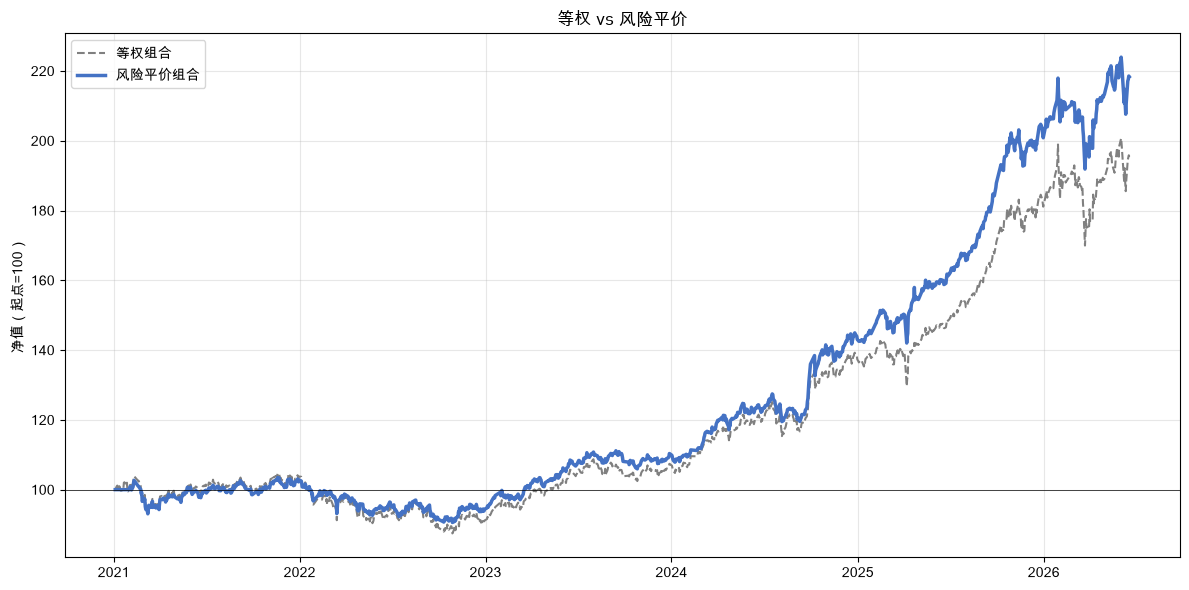

In [7]:
# 净值曲线对比（仅共同交易日，避免日历差异造成锯齿）
fig, ax = plt.subplots(figsize=(12, 6))

eq_ew = pd.Series(dict(result_ew.equity_curve)).reindex(common_trading_days).dropna()
eq_rp = pd.Series(dict(result_rp.equity_curve)).reindex(common_trading_days).dropna()
eq_ew_norm = eq_ew / eq_ew.iloc[0] * 100
eq_rp_norm = eq_rp / eq_rp.iloc[0] * 100

ax.plot(eq_ew_norm.index, eq_ew_norm.values, label='等权组合',
        linestyle='--', color='gray', linewidth=1.5)
ax.plot(eq_rp_norm.index, eq_rp_norm.values, label='风险平价组合',
        color='#4472C4', linewidth=2.5)

ax.axhline(y=100, color='black', linestyle='-', linewidth=0.5)
ax.set_ylabel('净值（起点=100）')
ax.set_title('等权 vs 风险平价')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02-ew-vs-rp-nav.png", dpi=150, bbox_inches='tight')
plt.show()

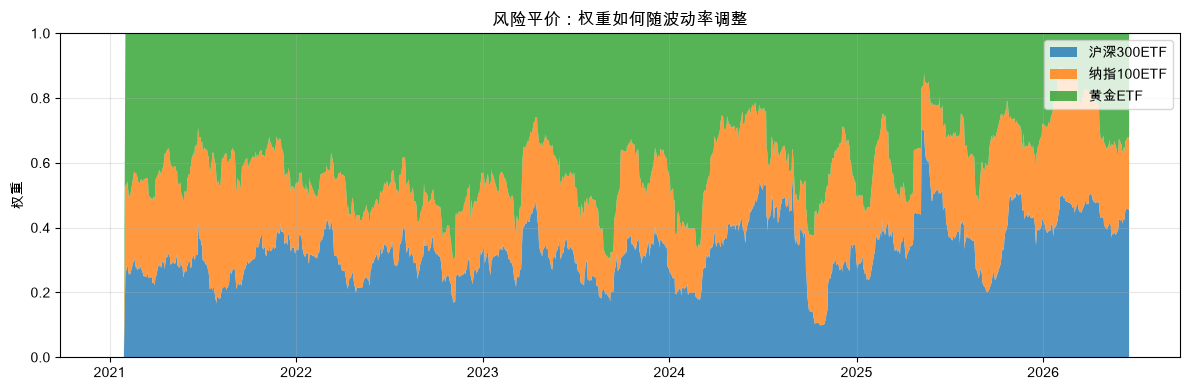

波动大的少买点、波动小的多买点——
组合波动率从 13.30% 降到 11.93%，最大回撤从 -16.47% 收窄到 -12.44%。

这种方法叫风险平价（Risk Parity）——让每个资产对组合波动的贡献一样大。
桥水基金的‘全天候策略’用的就是这个思路。


In [8]:
# 权重变化历史图（从回测结果提取）
fig, ax = plt.subplots(figsize=(12, 4))

# 用回测结果的 weights_df，重命名列为中文
weight_df = rp_weights_df.rename(columns=SYMBOL_NAMES).reindex(common_trading_days).dropna()

ax.stackplot(weight_df.index, [weight_df[SYMBOL_NAMES[s]].values for s in SYMBOLS],
             labels=[SYMBOL_NAMES[s] for s in SYMBOLS],
             alpha=0.8)
ax.set_ylabel('权重')
ax.set_title('风险平价：权重如何随波动率调整')
ax.legend(loc='upper right')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03-rp-weight-history.png", dpi=150, bbox_inches='tight')
plt.show()

# 分析
print(f"波动大的少买点、波动小的多买点——")
print(f"组合波动率从 {ew_vol:.2%} 降到 {rp_vol:.2%}，最大回撤从 {ew_dd:.2%} 收窄到 {rp_dd:.2%}。")
print(f"\n这种方法叫风险平价（Risk Parity）——让每个资产对组合波动的贡献一样大。")
print(f"桥水基金的\u2018全天候策略\u2019用的就是这个思路。")

### Step 2 解读

权重对比表一目了然：风险平价给波动低的资产分配了更多的钱，给波动高的分配了更少的钱。

效果呢？**波动率降了，回撤也小了。** 堆叠面积图还展示了一个细节：权重不是一成不变的——随着市场波动变化，每只 ETF 分到的比例也在动态调整。

这种方法叫**风险平价（Risk Parity）**。名字听起来高级，道理很朴素：

> 想象你要把一笔钱交给三个人打理。一个人成熟稳重，赚了不炫亏了不慌；一个人喜怒无常，今天信心爆棚明天就要清仓；第三个人介于两者之间。你会怎么分？肯定是稳重的那个多管点钱，情绪化的那个少管点。三只 ETF也一样——波动率就是它们的"情绪起伏程度"。波动小的稳重，多买；波动大的情绪化，少买。这就是按波动率倒数分配权重的直觉。

这里的"情绪"就是波动率，"管理钱"就是主导了组合的涨跌。波动大的少买点、波动小的多买点。桥水基金的"全天候策略"用的就是这个思路。

**数据说了算：按波动调整比例，确实比拍脑袋平均分更稳。**

---

## Practice: 加入 BTC-USD 做 RiskParity 对照实验

这一段不修改原参考 notebook，只在 practice 副本中做一个公平对照：

1. 原三资产等权
2. 原三资产 RiskParity
3. 加 BTC-USD 后等权
4. 加 BTC-USD 后 RiskParity

为了避免 BTC 周末交易和 ETF 交易日不同导致回测在周末变成“只剩 BTC”，下面把 BTC 价格对齐到原三只 ETF 的共同交易日，使用截至该交易日的最新 BTC 收盘价。

In [9]:
# 下载并加载 BTC-USD；四资产实验统一在当前 xquant 目录执行
BTC_SYMBOL = "BTC-USD"
SYMBOLS_WITH_BTC = SYMBOLS + (BTC_SYMBOL,)
SYMBOL_NAMES_WITH_BTC = {
    **SYMBOL_NAMES,
    BTC_SYMBOL: "BTC",
}

for sym in SYMBOLS_WITH_BTC:
    downloader.download(sym, start=START, end=today)

raw_market = LocalMarketDataProvider(currency="USD")
raw_mktdata = {sym: raw_market.get_bars(sym, START, today).copy() for sym in SYMBOLS_WITH_BTC}

print("四资产数据加载完成")
for sym in SYMBOLS_WITH_BTC:
    df = raw_mktdata[sym]
    print(f"  {SYMBOL_NAMES_WITH_BTC[sym]}: {len(df)} 行，{df.index[0].date()} 到 {df.index[-1].date()}")

四资产数据加载完成
  沪深300ETF: 1320 行，2021-01-04 到 2026-06-18
  纳指100ETF: 1321 行，2021-01-04 到 2026-06-18
  黄金ETF: 1320 行，2021-01-04 到 2026-06-18
  BTC: 1997 行，2021-01-01 到 2026-06-20


In [10]:
# 将 BTC 对齐到原三只 ETF 的共同交易日，避免混合交易日历扭曲权重

def normalize_to_session_index(df):
    out = df.copy()
    session_dates = [pd.Timestamp(ts).date() for ts in out.index]
    out.index = pd.DatetimeIndex(session_dates).tz_localize("Asia/Shanghai")
    out = out[~out.index.duplicated(keep="last")].sort_index()
    out.attrs.update(df.attrs)
    return out

normalized_data = {sym: normalize_to_session_index(df) for sym, df in raw_mktdata.items()}

base_sessions = normalized_data[SYMBOLS[0]].index
for sym in SYMBOLS[1:]:
    base_sessions = base_sessions.intersection(normalized_data[sym].index)
base_sessions = base_sessions.sort_values()

aligned_data = {}
for sym in SYMBOLS_WITH_BTC:
    df = normalized_data[sym].copy()
    if sym == BTC_SYMBOL:
        df = df.reindex(df.index.union(base_sessions)).sort_index().ffill().reindex(base_sessions)
    else:
        df = df.reindex(base_sessions)
    df = df.dropna(subset=["close"])
    df.attrs["currency"] = "USD"
    df.attrs["timezone"] = "Asia/Shanghai"
    aligned_data[sym] = df

common_sessions = base_sessions
for sym, df in aligned_data.items():
    common_sessions = common_sessions.intersection(df.index)
common_sessions = common_sessions.sort_values()
aligned_data = {sym: df.reindex(common_sessions).copy() for sym, df in aligned_data.items()}

class InMemoryMarketDataProvider:
    def __init__(self, data, currency="USD"):
        self.data = data
        self.currency = currency

    def get_bars(self, symbol, start, end):
        df = self.data[symbol].loc[start:end].copy()
        df.attrs["currency"] = self.currency
        df.attrs["timezone"] = "Asia/Shanghai"
        return df

    def get_latest(self, symbol):
        df = self.get_bars(symbol, START, today)
        return df.iloc[-1]

aligned_market_3 = InMemoryMarketDataProvider({sym: aligned_data[sym] for sym in SYMBOLS})
aligned_market_4 = InMemoryMarketDataProvider({sym: aligned_data[sym] for sym in SYMBOLS_WITH_BTC})

print(f"共同交易日：{len(common_sessions)} 天，{common_sessions[0].date()} 到 {common_sessions[-1].date()}")
print("说明：BTC 使用最新可得日收盘价对齐到 ETF 交易日；四个组合在同一组交易日上比较。")

共同交易日：1320 天，2021-01-04 到 2026-06-18
说明：BTC 使用最新可得日收盘价对齐到 ETF 交易日；四个组合在同一组交易日上比较。


In [11]:
# 策略与指标辅助函数

def make_threshold_signal_with_vol():
    signal = Threshold()
    signal.required_indicators = {
        "vol": (RollingVolatility(), {"column": "close", "period": 20}),
    }
    return signal


def run_allocation_strategy(name, symbols, optimizer, market_provider):
    signal = make_threshold_signal_with_vol()
    strategy = Strategy(
        name=name,
        universe=StaticUniverse(symbols=symbols, name=name),
        signals={"active": (signal, {"column": "close", "threshold": 0, "relationship": "gt"})},
        portfolio=optimizer,
    )
    return Engine().run(
        strategy,
        market=market_provider,
        broker=SimBroker(),
        start=START,
        end=today,
        rules=[RebalanceFrequencyRule(interval_days=10)],
    )


def equity_series(result):
    s = pd.Series(dict(result.equity_curve)).sort_index()
    s.index = pd.DatetimeIndex(s.index)
    return s


def metric_row(result):
    return {
        "累计收益": result.total_return(),
        "年化收益": result.annualized_return(),
        "年化波动": result.annualized_volatility(),
        "最大回撤": result.max_drawdown(),
        "夏普": result.sharpe_ratio(),
        "卡玛": result.calmar_ratio(),
    }


def format_metric_table(df):
    out = df.copy()
    percent_cols = ["累计收益", "年化收益", "年化波动", "最大回撤"]
    for col in percent_cols:
        out[col] = out[col].map(lambda x: f"{x:.2%}")
    for col in ["夏普", "卡玛"]:
        out[col] = out[col].map(lambda x: f"{x:.2f}")
    return out


def annual_returns(result):
    s = equity_series(result)
    return s.groupby(s.index.year).apply(lambda x: x.iloc[-1] / x.iloc[0] - 1)


def format_percent_table(df):
    return df.map(lambda x: "" if pd.isna(x) else f"{x:.2%}")

In [12]:
# 四组组合：原三资产等权 / 原三资产 RiskParity / 加 BTC 等权 / 加 BTC RiskParity
result_ew3_aligned = run_allocation_strategy(
    "三资产等权",
    SYMBOLS,
    EqualWeightOptimizer(),
    aligned_market_3,
)
result_rp3_aligned = run_allocation_strategy(
    "三资产RiskParity",
    SYMBOLS,
    RiskParityOptimizer(volatility_col="vol"),
    aligned_market_3,
)
result_ew4 = run_allocation_strategy(
    "加BTC等权",
    SYMBOLS_WITH_BTC,
    EqualWeightOptimizer(),
    aligned_market_4,
)
result_rp4 = run_allocation_strategy(
    "加BTCRiskParity",
    SYMBOLS_WITH_BTC,
    RiskParityOptimizer(volatility_col="vol"),
    aligned_market_4,
)

results = {
    "原三资产等权": result_ew3_aligned,
    "原三资产RiskParity": result_rp3_aligned,
    "加BTC后等权": result_ew4,
    "加BTC后RiskParity": result_rp4,
}

summary = pd.DataFrame({name: metric_row(result) for name, result in results.items()}).T
summary_formatted = format_metric_table(summary)
print("四组策略指标对比")
display(summary_formatted)
summary.to_csv(OUTPUT_DIR / "btc_comparison_metrics.csv", encoding="utf-8-sig")

四组策略指标对比


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛
原三资产等权,95.51%,13.67%,13.25%,-16.47%,1.04,0.83
原三资产RiskParity,114.53%,15.70%,11.81%,-12.44%,1.30,1.26
加BTC后等权,97.55%,13.89%,11.24%,-14.89%,1.21,0.93
加BTC后RiskParity,96.28%,13.75%,10.66%,-11.49%,1.26,1.20


In [13]:
# 最新权重与 BTC 权重是否被 RiskParity 自然压低
latest_date = common_sessions[-1]
weights = {name: result.weights_df().reindex(common_sessions).ffill().fillna(0) for name, result in results.items()}

weight_compare = pd.DataFrame(index=list(SYMBOLS_WITH_BTC))
for name, wdf in weights.items():
    weight_compare[name] = [wdf[sym].iloc[-1] if sym in wdf.columns else 0.0 for sym in SYMBOLS_WITH_BTC]
weight_compare.index = [SYMBOL_NAMES_WITH_BTC[sym] for sym in SYMBOLS_WITH_BTC]

print(f"最新目标权重（{latest_date.date()}）")
display(weight_compare.map(lambda x: f"{x:.2%}"))

btc_weight_stats = pd.DataFrame({
    "最新权重": {
        "加BTC后等权": weight_compare.loc["BTC", "加BTC后等权"],
        "加BTC后RiskParity": weight_compare.loc["BTC", "加BTC后RiskParity"],
    },
    "平均权重": {
        "加BTC后等权": weights["加BTC后等权"][BTC_SYMBOL].mean(),
        "加BTC后RiskParity": weights["加BTC后RiskParity"][BTC_SYMBOL].mean(),
    },
    "最高权重": {
        "加BTC后等权": weights["加BTC后等权"][BTC_SYMBOL].max(),
        "加BTC后RiskParity": weights["加BTC后RiskParity"][BTC_SYMBOL].max(),
    },
})
print("BTC 权重统计")
display(btc_weight_stats.map(lambda x: f"{x:.2%}"))
weight_compare.to_csv(OUTPUT_DIR / "latest_weights.csv", encoding="utf-8-sig")
btc_weight_stats.to_csv(OUTPUT_DIR / "btc_weight_stats.csv", encoding="utf-8-sig")

最新目标权重（2026-06-18）


,原三资产等权,原三资产RiskParity,加BTC后等权,加BTC后RiskParity
沪深300ETF,33.33%,45.96%,25.00%,38.30%
纳指100ETF,33.33%,21.86%,25.00%,18.22%
黄金ETF,33.33%,32.18%,25.00%,26.82%
BTC,0.00%,0.00%,25.00%,16.65%


BTC 权重统计


,最新权重,平均权重,最高权重
加BTC后等权,25.00%,25.00%,25.00%
加BTC后RiskParity,16.65%,9.05%,23.07%


In [14]:
# 年度收益对比，以及年度收益稳定性
annual_table = pd.DataFrame({name: annual_returns(result) for name, result in results.items()})
annual_table.index.name = "年份"
annual_std = annual_table.std(skipna=True)

print("年度收益")
display(format_percent_table(annual_table))
print("年度收益标准差（越高代表年度表现越不稳定）")
display(annual_std.to_frame("年度收益标准差").T.map(lambda x: f"{x:.2%}"))
annual_table.to_csv(OUTPUT_DIR / "annual_returns.csv", encoding="utf-8-sig")

年度收益


,原三资产等权,原三资产RiskParity,加BTC后等权,加BTC后RiskParity
年份,,,,
2021,3.77%,2.79%,2.90%,2.53%
2022,-12.10%,-7.91%,-12.83%,-7.49%
2023,17.28%,16.47%,39.27%,15.25%
2024,28.47%,30.22%,20.87%,27.38%
2025,32.42%,40.28%,23.67%,34.54%
2026,6.02%,5.25%,4.65%,3.75%


年度收益标准差（越高代表年度表现越不稳定）


,原三资产等权,原三资产RiskParity,加BTC后等权,加BTC后RiskParity
年度收益标准差,16.72%,18.11%,18.46%,16.06%


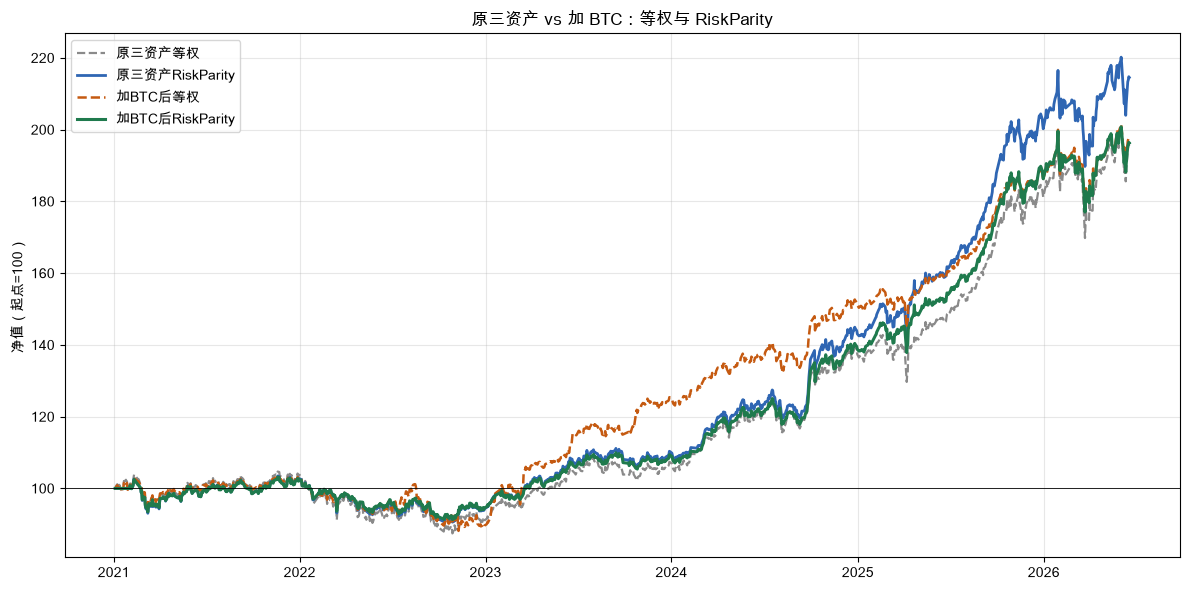

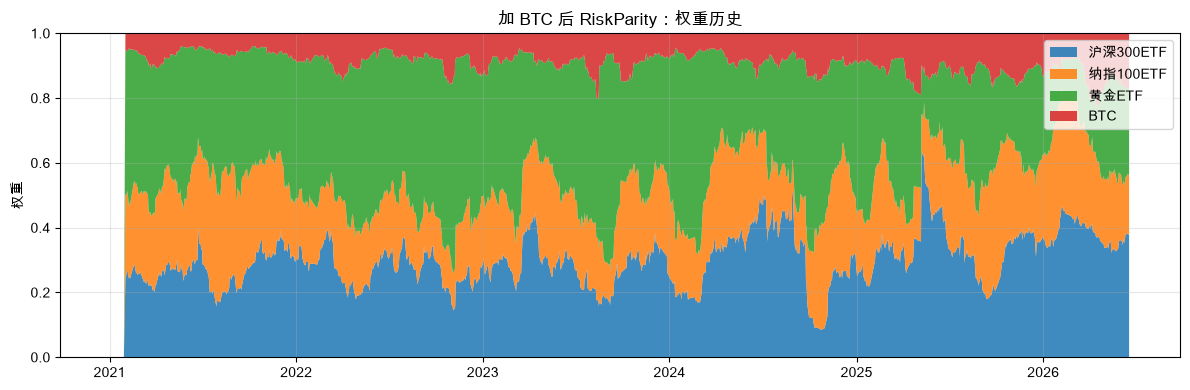

In [15]:
# 净值曲线和 RiskParity 权重历史图
fig, ax = plt.subplots(figsize=(12, 6))
plot_styles = {
    "原三资产等权": {"color": "#8A8A8A", "linestyle": "--", "linewidth": 1.6},
    "原三资产RiskParity": {"color": "#2F66B3", "linestyle": "-", "linewidth": 2.0},
    "加BTC后等权": {"color": "#C55A11", "linestyle": "--", "linewidth": 1.8},
    "加BTC后RiskParity": {"color": "#1F7A4D", "linestyle": "-", "linewidth": 2.2},
}
for name, result in results.items():
    eq = equity_series(result).reindex(common_sessions).dropna()
    norm = eq / eq.iloc[0] * 100
    ax.plot(norm.index, norm.values, label=name, **plot_styles[name])
ax.axhline(100, color="black", linewidth=0.6)
ax.set_title("原三资产 vs 加 BTC：等权与 RiskParity")
ax.set_ylabel("净值（起点=100）")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "btc_four_strategy_nav.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
rp4_weights = weights["加BTC后RiskParity"][[sym for sym in SYMBOLS_WITH_BTC if sym in weights["加BTC后RiskParity"].columns]]
rp4_weights = rp4_weights.rename(columns=SYMBOL_NAMES_WITH_BTC)
ax.stackplot(rp4_weights.index, [rp4_weights[col].values for col in rp4_weights.columns], labels=rp4_weights.columns, alpha=0.86)
ax.set_title("加 BTC 后 RiskParity：权重历史")
ax.set_ylabel("权重")
ax.set_ylim(0, 1)
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "btc_riskparity_weight_history.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# 自动生成结论，便于复盘

def pct(x):
    return f"{x:.2%}"

ret_ew_delta = summary.loc["加BTC后等权", "累计收益"] - summary.loc["原三资产等权", "累计收益"]
vol_ew_delta = summary.loc["加BTC后等权", "年化波动"] - summary.loc["原三资产等权", "年化波动"]
ret_rp_delta = summary.loc["加BTC后RiskParity", "累计收益"] - summary.loc["原三资产RiskParity", "累计收益"]
vol_rp_delta = summary.loc["加BTC后RiskParity", "年化波动"] - summary.loc["原三资产RiskParity", "年化波动"]

dd_ew_worse = summary.loc["加BTC后等权", "最大回撤"] < summary.loc["原三资产等权", "最大回撤"]
dd_rp_worse = summary.loc["加BTC后RiskParity", "最大回撤"] < summary.loc["原三资产RiskParity", "最大回撤"]

btc_latest_ew = btc_weight_stats.loc["加BTC后等权", "最新权重"]
btc_latest_rp = btc_weight_stats.loc["加BTC后RiskParity", "最新权重"]
btc_avg_ew = btc_weight_stats.loc["加BTC后等权", "平均权重"]
btc_avg_rp = btc_weight_stats.loc["加BTC后RiskParity", "平均权重"]

print("结论")
print("=" * 60)
print(f"1. BTC 对等权组合：累计收益变化 {pct(ret_ew_delta)}，年化波动变化 {pct(vol_ew_delta)}。")
print(f"   BTC 对 RiskParity：累计收益变化 {pct(ret_rp_delta)}，年化波动变化 {pct(vol_rp_delta)}。")
print(f"2. RiskParity 是否降低 BTC 权重：等权最新/平均 BTC 权重为 {pct(btc_latest_ew)} / {pct(btc_avg_ew)}；RiskParity 为 {pct(btc_latest_rp)} / {pct(btc_avg_rp)}。")
print(f"3. 最大回撤：等权 {'恶化' if dd_ew_worse else '没有恶化'}（{pct(summary.loc['原三资产等权', '最大回撤'])} -> {pct(summary.loc['加BTC后等权', '最大回撤'])}）；RiskParity {'恶化' if dd_rp_worse else '没有恶化'}（{pct(summary.loc['原三资产RiskParity', '最大回撤'])} -> {pct(summary.loc['加BTC后RiskParity', '最大回撤'])}）。")
print(f"4. 年度收益稳定性：等权年度收益标准差 {pct(annual_std['原三资产等权'])} -> {pct(annual_std['加BTC后等权'])}；RiskParity {pct(annual_std['原三资产RiskParity'])} -> {pct(annual_std['加BTC后RiskParity'])}。")

if ret_ew_delta > 0 and vol_ew_delta > 0:
    print("\n简短判断：在等权里，BTC 确实提高收益，但同时显著抬高波动，需要看夏普/卡玛是否补偿了风险。")
elif ret_ew_delta <= 0 and vol_ew_delta > 0:
    print("\n简短判断：在等权里，BTC 更像是在增加波动，而不是贡献收益。")
else:
    print("\n简短判断：BTC 对等权组合的收益/波动影响不属于简单的单向恶化，要结合风险调整指标看。")

if btc_avg_rp < btc_avg_ew:
    print("RiskParity 会自然压低 BTC 权重，因为 BTC 的 20 日波动率通常高于 ETF。")
else:
    print("RiskParity 没有压低 BTC 平均权重，需要检查样本期内 BTC 波动率与 ETF 的相对关系。")

结论
1. BTC 对等权组合：累计收益变化 2.05%，年化波动变化 -2.01%。
   BTC 对 RiskParity：累计收益变化 -18.25%，年化波动变化 -1.15%。
2. RiskParity 是否降低 BTC 权重：等权最新/平均 BTC 权重为 25.00% / 25.00%；RiskParity 为 16.65% / 9.05%。
3. 最大回撤：等权 没有恶化（-16.47% -> -14.89%）；RiskParity 没有恶化（-12.44% -> -11.49%）。
4. 年度收益稳定性：等权年度收益标准差 16.72% -> 18.46%；RiskParity 18.11% -> 16.06%。

简短判断：BTC 对等权组合的收益/波动影响不属于简单的单向恶化，要结合风险调整指标看。
RiskParity 会自然压低 BTC 权重，因为 BTC 的 20 日波动率通常高于 ETF。


---

## Q5 Practice: 用更多评估角度重新看加 BTC

Q3 的指标已经回答了收益、波动、回撤。Q5 会提醒我们：策略不能只看一个平均结果，还要看它有没有跑赢基准、下行风险如何、每年和每月的体验如何、回撤要熬多久，以及参数稍微变动后结论会不会崩。

这里仍然只比较四个和 BTC 问题直接相关的组合：原三资产等权、原三资产 RiskParity、加 BTC 后等权、加 BTC 后 RiskParity。

In [17]:
# Q5 评估辅助函数：基准、Alpha、索提诺、月度结构、回撤事件、参数敏感性

def max_consecutive(mask):
    longest = 0
    current = 0
    for value in mask:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def monthly_stats(result):
    months = result.monthly_returns().dropna()
    gains = months[months > 0]
    losses = months[months < 0]
    total_gain = gains.sum()
    total_loss = losses.sum()
    avg_gain = gains.mean() if len(gains) else 0.0
    avg_loss = losses.mean() if len(losses) else 0.0
    return {
        "总月数": len(months),
        "盈利月数": len(gains),
        "亏损月数": len(losses),
        "胜率": len(gains) / len(months) if len(months) else 0.0,
        "平均盈利月": avg_gain,
        "平均亏损月": avg_loss,
        "盈亏比": avg_gain / abs(avg_loss) if avg_loss != 0 else np.nan,
        "盈亏因子": total_gain / abs(total_loss) if total_loss != 0 else np.nan,
        "中位数月收益": months.median() if len(months) else 0.0,
        "最好月": months.max() if len(months) else 0.0,
        "最差月": months.min() if len(months) else 0.0,
        "最长连赢": max_consecutive(months > 0),
        "最长连亏": max_consecutive(months < 0),
    }


def drawdown_events(result):
    dd = result.drawdown_series().sort_index()
    events = []
    in_dd = False
    start = trough = recovery = None
    trough_value = 0.0

    for date, value in dd.items():
        if not in_dd and value < 0:
            in_dd = True
            start = date
            trough = date
            trough_value = value
        elif in_dd:
            if value < trough_value:
                trough = date
                trough_value = value
            if value >= 0:
                recovery = date
                events.append({
                    "开始日期": pd.Timestamp(start).date(),
                    "最低点日期": pd.Timestamp(trough).date(),
                    "恢复日期": pd.Timestamp(recovery).date(),
                    "深度": trough_value,
                    "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
                    "恢复天数": (pd.Timestamp(recovery) - pd.Timestamp(trough)).days,
                    "总持续天数": (pd.Timestamp(recovery) - pd.Timestamp(start)).days,
                })
                in_dd = False
                start = trough = recovery = None
                trough_value = 0.0

    if in_dd and start is not None and trough is not None:
        last_date = dd.index[-1]
        events.append({
            "开始日期": pd.Timestamp(start).date(),
            "最低点日期": pd.Timestamp(trough).date(),
            "恢复日期": "未恢复",
            "深度": trough_value,
            "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
            "恢复天数": np.nan,
            "总持续天数": (pd.Timestamp(last_date) - pd.Timestamp(start)).days,
        })

    if not events:
        return pd.DataFrame(columns=["开始日期", "最低点日期", "恢复日期", "深度", "下跌天数", "恢复天数", "总持续天数"])
    return pd.DataFrame(events).sort_values("深度")


def drawdown_summary(result):
    events = drawdown_events(result)
    if events.empty:
        return {"最大回撤": 0.0, "平均回撤深度": 0.0, "平均恢复天数": 0.0, "最长恢复天数": 0.0, "回撤次数": 0}
    recovered = events.dropna(subset=["恢复天数"])
    return {
        "最大回撤": events["深度"].min(),
        "平均回撤深度": events["深度"].mean(),
        "平均恢复天数": recovered["恢复天数"].mean() if len(recovered) else np.nan,
        "最长恢复天数": recovered["恢复天数"].max() if len(recovered) else np.nan,
        "回撤次数": len(events),
    }


def buy_and_hold_equal(symbols, data):
    prices = pd.DataFrame({sym: data[sym]["close"] for sym in symbols}).dropna()
    nav = prices.divide(prices.iloc[0]).mean(axis=1) * 100_000
    return nav


def series_metrics(nav):
    returns = nav.pct_change().dropna()
    log_returns = np.log(nav).diff().dropna()
    total = nav.iloc[-1] / nav.iloc[0] - 1
    annual = (nav.iloc[-1] / nav.iloc[0]) ** (252 / (len(nav) - 1)) - 1
    vol = log_returns.std(ddof=1) * np.sqrt(252)
    dd = (nav / nav.cummax() - 1).min()
    sharpe = returns.mean() / returns.std(ddof=0) * np.sqrt(252) if returns.std(ddof=0) != 0 else 0.0
    downside = log_returns[log_returns < 0]
    sortino = (log_returns.mean() * 252) / (np.sqrt((downside ** 2).mean()) * np.sqrt(252)) if len(downside) else 0.0
    calmar = annual / abs(dd) if dd != 0 else 0.0
    return {"累计收益": total, "年化收益": annual, "年化波动": vol, "最大回撤": dd, "夏普": sharpe, "卡玛": calmar, "索提诺": sortino}


def metric_row_q5(result):
    row = metric_row(result)
    row["索提诺"] = result.sortino_ratio()
    return row


def fmt_q5_table(df):
    out = df.copy()
    for col in ["累计收益", "年化收益", "年化波动", "最大回撤", "Alpha"]:
        if col in out.columns:
            out[col] = out[col].map(lambda x: f"{x:.2%}")
    for col in ["夏普", "卡玛", "索提诺", "盈亏比", "盈亏因子"]:
        if col in out.columns:
            out[col] = out[col].map(lambda x: "—" if pd.isna(x) else f"{x:.2f}")
    return out

In [18]:
# 1) 策略 vs 买入持有基准：加入 Alpha 和索提诺
benchmark_3_nav = buy_and_hold_equal(SYMBOLS, aligned_data)
benchmark_4_nav = buy_and_hold_equal(SYMBOLS_WITH_BTC, aligned_data)
benchmark_rows = {
    "三资产买入持有基准": series_metrics(benchmark_3_nav),
    "四资产买入持有基准": series_metrics(benchmark_4_nav),
}

q5_summary = pd.DataFrame({name: metric_row_q5(result) for name, result in results.items()}).T
q5_full = pd.concat([q5_summary, pd.DataFrame(benchmark_rows).T], axis=0)
q5_full["Alpha"] = q5_full["累计收益"] - q5_full.loc["三资产买入持有基准", "累计收益"]

print("Q5 视角：策略 vs 买入持有基准")
display(fmt_q5_table(q5_full[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "索提诺", "Alpha"]]))
q5_full.to_csv(OUTPUT_DIR / "q5_btc_strategy_vs_benchmark.csv", encoding="utf-8-sig")

Q5 视角：策略 vs 买入持有基准


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,Alpha
原三资产等权,95.51%,13.67%,13.25%,-16.47%,1.04,0.83,0.90,-2.63%
原三资产RiskParity,114.53%,15.70%,11.81%,-12.44%,1.30,1.26,1.17,16.39%
加BTC后等权,97.55%,13.89%,11.24%,-14.89%,1.21,0.93,1.13,-0.59%
加BTC后RiskParity,96.28%,13.75%,10.66%,-11.49%,1.26,1.20,1.14,-1.86%
三资产买入持有基准,98.14%,13.96%,14.02%,-17.24%,1.01,0.81,0.86,0.00%
四资产买入持有基准,97.79%,13.92%,21.25%,-39.13%,0.72,0.36,0.62,-0.35%


Q5 视角：逐年收益


,原三资产等权,原三资产RiskParity,加BTC后等权,加BTC后RiskParity,三资产买入持有基准,四资产买入持有基准
年份,,,,,,
2021,3.77%,2.79%,2.90%,2.53%,4.09%,14.28%
2022,-12.10%,-7.91%,-12.83%,-7.49%,-13.45%,-29.31%
2023,17.28%,16.47%,39.27%,15.25%,20.74%,41.97%
2024,28.47%,30.22%,20.87%,27.38%,28.61%,52.44%
2025,32.42%,40.28%,23.67%,34.54%,31.91%,14.50%
2026,6.02%,5.25%,4.65%,3.75%,5.17%,-7.88%


负收益年份数量


,原三资产等权,原三资产RiskParity,加BTC后等权,加BTC后RiskParity,三资产买入持有基准,四资产买入持有基准
负收益年份数,1,1,1,1,1,2


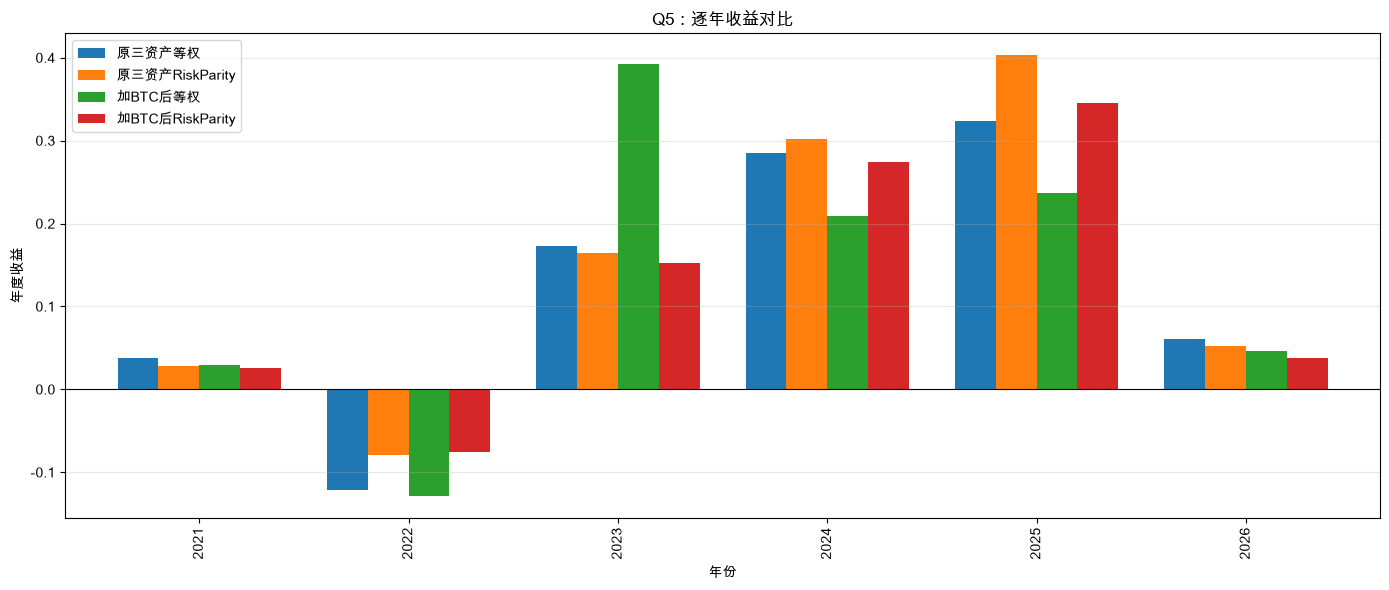

In [19]:
# 2) 逐年收益：看是不是靠某一年撑起来
q5_annual = annual_table.copy()
q5_annual["三资产买入持有基准"] = benchmark_3_nav.groupby(benchmark_3_nav.index.year).apply(lambda x: x.iloc[-1] / x.iloc[0] - 1)
q5_annual["四资产买入持有基准"] = benchmark_4_nav.groupby(benchmark_4_nav.index.year).apply(lambda x: x.iloc[-1] / x.iloc[0] - 1)

print("Q5 视角：逐年收益")
display(format_percent_table(q5_annual))

negative_years = (q5_annual < 0).sum()
print("负收益年份数量")
display(negative_years.to_frame("负收益年份数").T)
q5_annual.to_csv(OUTPUT_DIR / "q5_btc_annual_returns.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(14, 6))
plot_df = q5_annual[["原三资产等权", "原三资产RiskParity", "加BTC后等权", "加BTC后RiskParity"]]
plot_df.plot(kind="bar", ax=ax, width=0.78)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Q5：逐年收益对比")
ax.set_ylabel("年度收益")
ax.legend(loc="upper left")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q5_btc_annual_returns.png", dpi=150, bbox_inches="tight")
plt.show()

Q5 视角：月度收益结构


/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:132: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_end = s.groupby(s.index.to_period("M")).last()
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:135: UserWarning: Converting to Period representation will drop timezone information.
  baseline = pd.Series([first_val], index=[s.index[0].to_period("M") - 1])
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:132: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_end = s.groupby(s.index.to_period("M")).last()
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:135: UserWarning: Converting to Period representation will drop timezone information.
  baseline = pd.Series([first_val], index=[s.index[0].to_period("

,总月数,盈利月数,亏损月数,胜率,平均盈利月,平均亏损月,盈亏比,盈亏因子,中位数月收益,最好月,最差月,最长连赢,最长连亏
原三资产等权,66.0,42.0,24.0,0.636364,0.027617,-0.018944,1.46,2.55,0.009674,0.095151,-0.079784,8.0,3.0
原三资产RiskParity,66.0,41.0,24.0,0.621212,0.029974,-0.017922,1.67,2.86,0.011808,0.108823,-0.070019,11.0,4.0
加BTC后等权,66.0,42.0,24.0,0.636364,0.026180,-0.016129,1.62,2.84,0.007641,0.106757,-0.059636,8.0,3.0
加BTC后RiskParity,66.0,41.0,24.0,0.621212,0.026758,-0.016418,1.63,2.78,0.010727,0.100463,-0.065166,11.0,4.0


/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:132: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_end = s.groupby(s.index.to_period("M")).last()
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:135: UserWarning: Converting to Period representation will drop timezone information.
  baseline = pd.Series([first_val], index=[s.index[0].to_period("M") - 1])
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:132: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_end = s.groupby(s.index.to_period("M")).last()
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:135: UserWarning: Converting to Period representation will drop timezone information.
  baseline = pd.Series([first_val], index=[s.index[0].to_period("

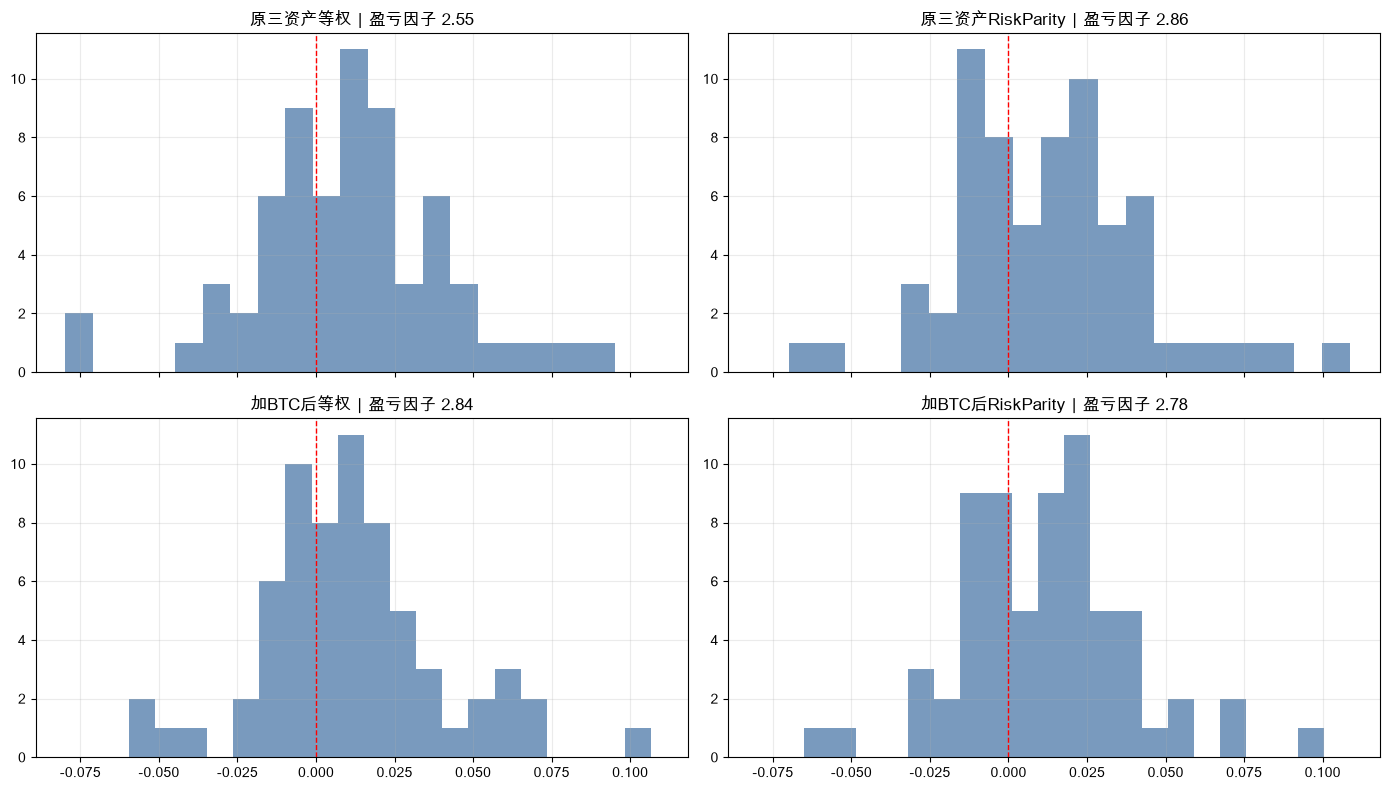

In [20]:
# 3) 月度收益结构：胜率不够，还要看赚的时候赚多少、亏的时候亏多少
q5_monthly = pd.DataFrame({name: monthly_stats(result) for name, result in results.items()}).T

print("Q5 视角：月度收益结构")
display(fmt_q5_table(q5_monthly[["总月数", "盈利月数", "亏损月数", "胜率", "平均盈利月", "平均亏损月", "盈亏比", "盈亏因子", "中位数月收益", "最好月", "最差月", "最长连赢", "最长连亏"]]))
q5_monthly.to_csv(OUTPUT_DIR / "q5_btc_monthly_stats.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (name, result) in zip(axes.ravel(), results.items()):
    monthly = result.monthly_returns().dropna()
    ax.hist(monthly, bins=20, color="#4C78A8", alpha=0.75)
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    pf = q5_monthly.loc[name, "盈亏因子"]
    ax.set_title(f"{name}｜盈亏因子 {pf:.2f}")
    ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q5_btc_monthly_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Q5 视角：回撤汇总


,最大回撤,平均回撤深度,平均恢复天数,最长恢复天数,回撤次数
原三资产等权,-16.47%,-1.98%,16,251,66
原三资产RiskParity,-12.44%,-1.86%,16,251,64
加BTC后等权,-14.89%,-1.35%,12,251,83
加BTC后RiskParity,-11.49%,-1.74%,17,253,60



原三资产等权 前 5 大回撤事件


,开始日期,最低点日期,恢复日期,深度,下跌天数,恢复天数,总持续天数
6,2021-11-22,2022-10-28,2023-06-15,-16.47%,340,230.0,570
64,2026-01-30,2026-03-23,2026-06-01,-14.69%,52,70.0,122
3,2021-02-18,2021-03-09,2021-11-15,-9.94%,19,251.0,270
32,2025-02-20,2025-04-07,2025-05-06,-9.16%,46,29.0,75
24,2024-07-18,2024-08-05,2024-09-26,-7.79%,18,52.0,70



原三资产RiskParity 前 5 大回撤事件


,开始日期,最低点日期,恢复日期,深度,下跌天数,恢复天数,总持续天数
4,2021-11-22,2022-10-28,2023-05-18,-12.44%,340,202.0,542
60,2026-01-30,2026-03-23,2026-05-11,-12.36%,52,49.0,101
1,2021-02-18,2021-03-09,2021-11-15,-9.34%,19,251.0,270
63,2026-06-03,2026-06-11,未恢复,-7.36%,8,NaN,15
25,2024-07-18,2024-08-05,2024-09-26,-6.24%,18,52.0,70



加BTC后等权 前 5 大回撤事件


,开始日期,最低点日期,恢复日期,深度,下跌天数,恢复天数,总持续天数
6,2021-11-22,2022-11-09,2023-03-17,-14.89%,352,128.0,480
81,2026-01-30,2026-03-23,2026-06-01,-11.18%,52,70.0,122
3,2021-02-18,2021-03-09,2021-11-15,-7.52%,19,251.0,270
49,2025-02-20,2025-04-07,2025-05-06,-6.90%,46,29.0,75
41,2024-07-18,2024-08-05,2024-09-26,-5.88%,18,52.0,70



加BTC后RiskParity 前 5 大回撤事件


,开始日期,最低点日期,恢复日期,深度,下跌天数,恢复天数,总持续天数
3,2021-11-22,2022-10-28,2023-05-19,-11.49%,340,203.0,543
58,2026-01-30,2026-03-23,2026-06-01,-11.30%,52,70.0,122
1,2021-02-18,2021-03-09,2021-11-17,-8.84%,19,253.0,272
59,2026-06-03,2026-06-11,未恢复,-6.29%,8,NaN,15
24,2024-07-18,2024-09-09,2024-09-26,-5.76%,53,17.0,70


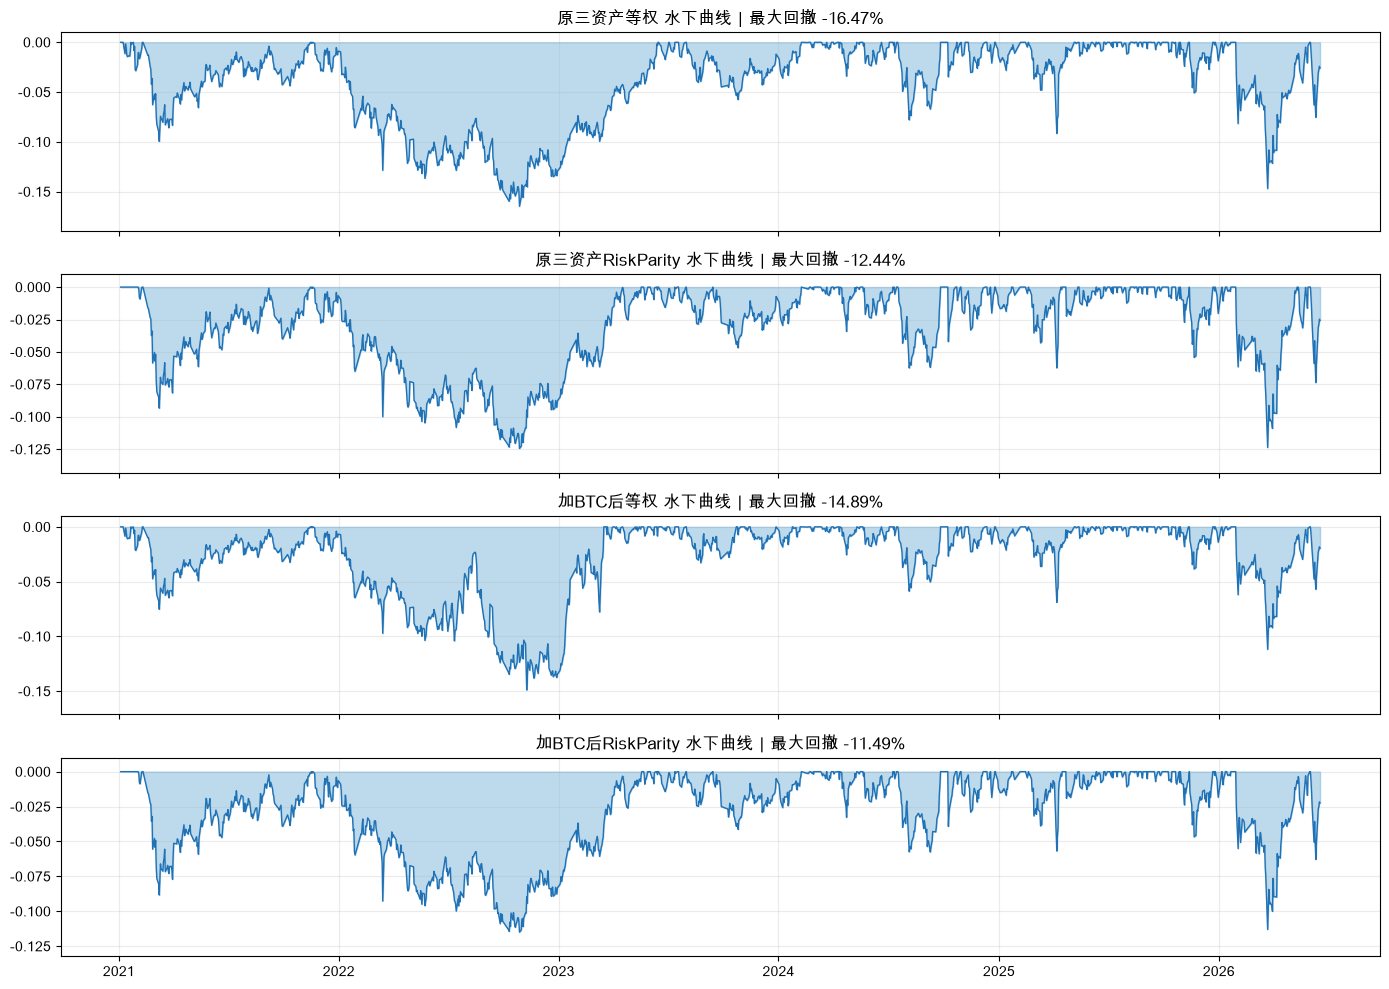

In [21]:
# 4) 回撤事件和水下曲线：看跌了多久、多久回本
q5_dd_summary = pd.DataFrame({name: drawdown_summary(result) for name, result in results.items()}).T

print("Q5 视角：回撤汇总")
display(format_metric_table(q5_dd_summary.rename(columns={"平均回撤深度": "最大回撤"})).rename(columns={"最大回撤": "平均回撤深度"}) if False else q5_dd_summary.assign(
    最大回撤=q5_dd_summary["最大回撤"].map(lambda x: f"{x:.2%}"),
    平均回撤深度=q5_dd_summary["平均回撤深度"].map(lambda x: f"{x:.2%}"),
    平均恢复天数=q5_dd_summary["平均恢复天数"].map(lambda x: "—" if pd.isna(x) else f"{x:.0f}"),
    最长恢复天数=q5_dd_summary["最长恢复天数"].map(lambda x: "—" if pd.isna(x) else f"{x:.0f}"),
    回撤次数=q5_dd_summary["回撤次数"].astype(int),
))
q5_dd_summary.to_csv(OUTPUT_DIR / "q5_btc_drawdown_summary.csv", encoding="utf-8-sig")

for name, result in results.items():
    events = drawdown_events(result).head(5)
    print(f"\n{name} 前 5 大回撤事件")
    if events.empty:
        print("无回撤事件")
    else:
        display(events.assign(深度=events["深度"].map(lambda x: f"{x:.2%}")))
        events.to_csv(OUTPUT_DIR / f"q5_drawdown_events_{name}.csv", encoding="utf-8-sig", index=False)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (name, result) in zip(axes, results.items()):
    dd = result.drawdown_series().sort_index()
    ax.fill_between(dd.index, dd.values, 0, color="#6BAED6", alpha=0.45)
    ax.plot(dd.index, dd.values, color="#2171B5", linewidth=1)
    ax.set_title(f"{name} 水下曲线｜最大回撤 {dd.min():.2%}")
    ax.set_ylim(min(dd.min() * 1.15, -0.02), 0.01)
    ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q5_btc_underwater_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Q5 视角：加 BTC 后 RiskParity 波动率窗口敏感性


,累计收益,年化波动,最大回撤,夏普,卡玛,索提诺,BTC平均权重
波动率窗口,,,,,,,
10,111.74%,10.93%,-11.90%,1.37,1.29,1.26,0.093085
15,95.35%,10.57%,-11.63%,1.27,1.17,1.14,0.091655
20,96.28%,10.66%,-11.49%,1.26,1.20,1.14,0.090503
25,97.82%,10.62%,-11.68%,1.28,1.19,1.15,0.089877
30,99.88%,10.73%,-12.11%,1.29,1.17,1.15,0.089382
40,114.69%,10.82%,-13.05%,1.41,1.20,1.28,0.088527


夏普比极差：0.14。极差越小，越像不依赖魔法参数的‘高原型’策略。


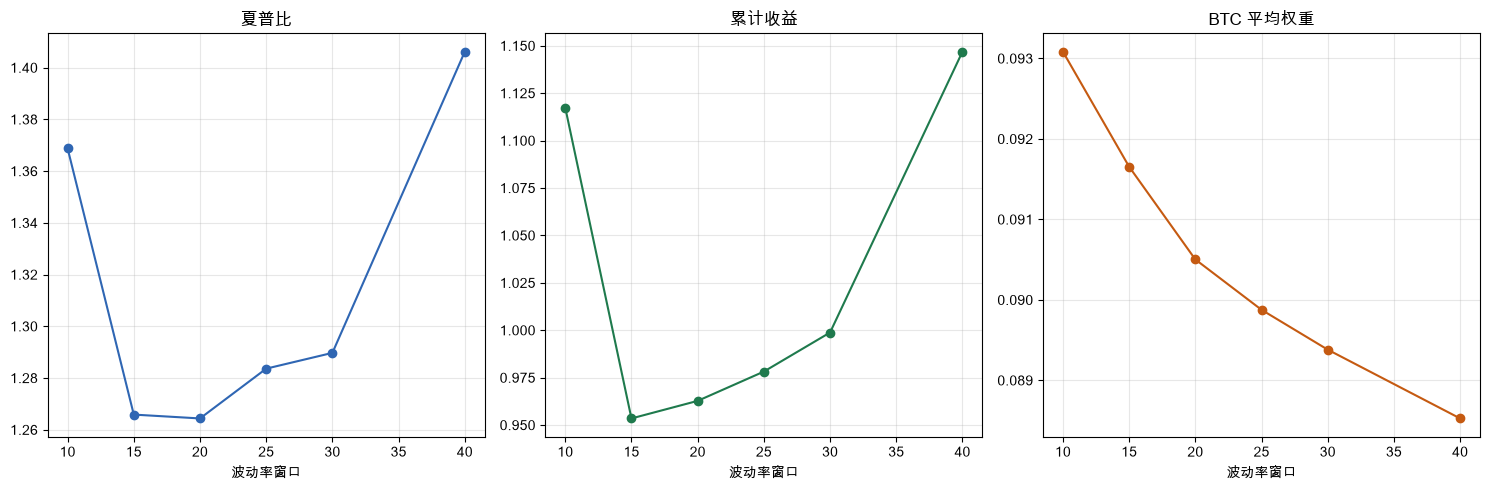

In [22]:
# 5) RiskParity 参数敏感性：加 BTC 后是不是依赖某个刚好选中的波动率窗口？
vol_periods = [10, 15, 20, 25, 30, 40]
sensitivity_rows = []
for period in vol_periods:
    signal = Threshold()
    signal.required_indicators = {"vol": (RollingVolatility(), {"column": "close", "period": period})}
    strategy = Strategy(
        name=f"btc-rp-vol-{period}",
        universe=StaticUniverse(symbols=SYMBOLS_WITH_BTC, name=f"btc-rp-vol-{period}"),
        signals={"active": (signal, {"column": "close", "threshold": 0, "relationship": "gt"})},
        portfolio=RiskParityOptimizer(volatility_col="vol"),
    )
    result = Engine().run(
        strategy,
        market=aligned_market_4,
        broker=SimBroker(),
        start=START,
        end=today,
        rules=[RebalanceFrequencyRule(interval_days=10)],
    )
    sensitivity_rows.append({
        "波动率窗口": period,
        "累计收益": result.total_return(),
        "年化波动": result.annualized_volatility(),
        "最大回撤": result.max_drawdown(),
        "夏普": result.sharpe_ratio(),
        "卡玛": result.calmar_ratio(),
        "索提诺": result.sortino_ratio(),
        "BTC平均权重": result.weights_df().reindex(common_sessions).ffill().fillna(0)[BTC_SYMBOL].mean(),
    })

q5_sensitivity = pd.DataFrame(sensitivity_rows)
print("Q5 视角：加 BTC 后 RiskParity 波动率窗口敏感性")
display(fmt_q5_table(q5_sensitivity.set_index("波动率窗口")))

sharpe_range = q5_sensitivity["夏普"].max() - q5_sensitivity["夏普"].min()
print(f"夏普比极差：{sharpe_range:.2f}。极差越小，越像不依赖魔法参数的‘高原型’策略。")
q5_sensitivity.to_csv(OUTPUT_DIR / "q5_btc_riskparity_vol_sensitivity.csv", encoding="utf-8-sig", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].plot(q5_sensitivity["波动率窗口"], q5_sensitivity["夏普"], marker="o", color="#2F66B3")
axes[0].set_title("夏普比")
axes[1].plot(q5_sensitivity["波动率窗口"], q5_sensitivity["累计收益"], marker="o", color="#1F7A4D")
axes[1].set_title("累计收益")
axes[2].plot(q5_sensitivity["波动率窗口"], q5_sensitivity["BTC平均权重"], marker="o", color="#C55A11")
axes[2].set_title("BTC 平均权重")
for ax in axes:
    ax.set_xlabel("波动率窗口")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "q5_btc_riskparity_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# Q5 综合结论：用更多尺子重新判断“加 BTC 好不好”

def pct2(x):
    return f"{x:.2%}"

base = q5_full.loc["原三资产RiskParity"]
btc_rp = q5_full.loc["加BTC后RiskParity"]
base_ew = q5_full.loc["原三资产等权"]
btc_ew = q5_full.loc["加BTC后等权"]

monthly_base = q5_monthly.loc["原三资产RiskParity"]
monthly_btc = q5_monthly.loc["加BTC后RiskParity"]
dd_base = q5_dd_summary.loc["原三资产RiskParity"]
dd_btc = q5_dd_summary.loc["加BTC后RiskParity"]

print("Q5 综合判断")
print("=" * 64)
print(f"1. 和原三资产 RiskParity 比，加 BTC 后累计收益 {pct2(base['累计收益'])} -> {pct2(btc_rp['累计收益'])}，Alpha {pct2(base['Alpha'])} -> {pct2(btc_rp['Alpha'])}。")
print(f"2. 风险调整后，加 BTC 后夏普 {base['夏普']:.2f} -> {btc_rp['夏普']:.2f}，卡玛 {base['卡玛']:.2f} -> {btc_rp['卡玛']:.2f}，索提诺 {base['索提诺']:.2f} -> {btc_rp['索提诺']:.2f}。")
print(f"3. 月度体验：胜率 {monthly_base['胜率']:.2%} -> {monthly_btc['胜率']:.2%}，盈亏因子 {monthly_base['盈亏因子']:.2f} -> {monthly_btc['盈亏因子']:.2f}，最差月 {monthly_base['最差月']:.2%} -> {monthly_btc['最差月']:.2%}。")
print(f"4. 回撤体验：最大回撤 {dd_base['最大回撤']:.2%} -> {dd_btc['最大回撤']:.2%}，最长恢复天数 {dd_base['最长恢复天数']:.0f} -> {dd_btc['最长恢复天数']:.0f}。")
print(f"5. 参数敏感性：加 BTC 后 RiskParity 的夏普极差是 {sharpe_range:.2f}，BTC 平均权重在 {q5_sensitivity['BTC平均权重'].min():.2%} 到 {q5_sensitivity['BTC平均权重'].max():.2%} 之间。")

print("\n通俗结论：")
if btc_rp['累计收益'] < base['累计收益'] and btc_rp['夏普'] < base['夏普']:
    print("对 RiskParity 来说，加 BTC 后更像是‘更稳一点，但赚少很多’，不是更好的升级。")
else:
    print("对 RiskParity 来说，加 BTC 的效果不是单纯变差，需要结合收益和风险承受偏好判断。")

if btc_ew['累计收益'] > base_ew['累计收益'] and btc_ew['夏普'] > base_ew['夏普']:
    print("对等权来说，BTC 有一点加分：收益和夏普都改善，但年度波动更不稳定，不能只看总收益。")
else:
    print("对等权来说，BTC 没有稳定地证明自己更好。")

print("如果目标是学习 Q3/Q5 的稳健配置，这组数据下仍然优先选原三资产 RiskParity；加 BTC 更像是一个研究对照，而不是必须加入的资产。")

Q5 综合判断
1. 和原三资产 RiskParity 比，加 BTC 后累计收益 114.53% -> 96.28%，Alpha 16.39% -> -1.86%。
2. 风险调整后，加 BTC 后夏普 1.30 -> 1.26，卡玛 1.26 -> 1.20，索提诺 1.17 -> 1.14。
3. 月度体验：胜率 62.12% -> 62.12%，盈亏因子 2.86 -> 2.78，最差月 -7.00% -> -6.52%。
4. 回撤体验：最大回撤 -12.44% -> -11.49%，最长恢复天数 251 -> 253。
5. 参数敏感性：加 BTC 后 RiskParity 的夏普极差是 0.14，BTC 平均权重在 8.85% 到 9.31% 之间。

通俗结论：
对 RiskParity 来说，加 BTC 后更像是‘更稳一点，但赚少很多’，不是更好的升级。
对等权来说，BTC 有一点加分：收益和夏普都改善，但年度波动更不稳定，不能只看总收益。
如果目标是学习 Q3/Q5 的稳健配置，这组数据下仍然优先选原三资产 RiskParity；加 BTC 更像是一个研究对照，而不是必须加入的资产。


---

## Q3/Q5 Practice: BTC 权重上限 + 趋势过滤

前面的实验说明：直接把 BTC 放进 RiskParity，会降低波动和回撤，但收益贡献不够。接下来测试一个更有纪律的版本：

1. **BTC RiskParity + 10% 权重上限**：BTC 可以进组合，但最多 10%。
2. **BTC RiskParity + 10% 权重上限 + 200 日均线趋势过滤**：BTC 只有在价格高于 200 日均线时才持有，否则 BTC 权重为 0，资金重新分给三只 ETF。

这仍然沿用 Q3/Q5 框架：先看收益、波动、回撤和权重，再看 Alpha、索提诺、年度/月度结构、回撤恢复时间和参数稳定性。

In [24]:
# BTC 有纪律加入：权重上限 + 趋势过滤
BTC_CAP = 0.10
BTC_TREND_MA = 200
BTC_TREND_COL = "btc_ma200"

# 给 BTC 预先加入 200 日均线。因为 aligned_market_4 是内存 provider，Engine 会保留这个额外列。
aligned_data[BTC_SYMBOL][BTC_TREND_COL] = aligned_data[BTC_SYMBOL]["close"].rolling(BTC_TREND_MA).mean()

class CappedRiskParityOptimizer:
    name = "CappedRiskParity"

    def __init__(self, volatility_col, caps=None, trend_symbol=None, trend_col=None):
        self.volatility_col = volatility_col
        self.caps = caps or {}
        self.trend_symbol = trend_symbol
        self.trend_col = trend_col

    def _eligible_symbols(self, indicators):
        eligible = []
        for symbol, df in indicators.items():
            if self.volatility_col not in df.columns:
                continue
            vol = float(df[self.volatility_col].iloc[-1])
            if pd.isna(vol) or vol <= 0:
                continue
            if symbol == self.trend_symbol:
                if self.trend_col not in df.columns:
                    continue
                close = float(df["close"].iloc[-1])
                trend = float(df[self.trend_col].iloc[-1])
                if pd.isna(trend) or close <= trend:
                    continue
            eligible.append(symbol)
        return eligible

    def optimize(self, signals, indicators):
        eligible = self._eligible_symbols(indicators)
        if not eligible:
            return {"CASH": 1.0}

        inv_vols = {symbol: 1.0 / float(indicators[symbol][self.volatility_col].iloc[-1]) for symbol in eligible}
        total_inv = sum(inv_vols.values())
        weights = {symbol: inv / total_inv for symbol, inv in inv_vols.items()}

        capped = {}
        uncapped_symbols = []
        remaining = 1.0
        for symbol, weight in weights.items():
            cap = self.caps.get(symbol)
            if cap is not None and weight > cap:
                capped[symbol] = cap
                remaining -= cap
            else:
                uncapped_symbols.append(symbol)

        if capped and uncapped_symbols:
            uncapped_total = sum(weights[symbol] for symbol in uncapped_symbols)
            for symbol in uncapped_symbols:
                capped[symbol] = remaining * weights[symbol] / uncapped_total if uncapped_total > 0 else 0.0
            weights = capped
        elif capped and not uncapped_symbols:
            weights = capped
            cash = 1.0 - sum(weights.values())
            if cash > 0:
                weights["CASH"] = cash

        return weights


def run_custom_optimizer_strategy(name, optimizer, symbols=SYMBOLS_WITH_BTC, market_provider=aligned_market_4, vol_period=20):
    signal = Threshold()
    signal.required_indicators = {
        "vol": (RollingVolatility(), {"column": "close", "period": vol_period}),
    }
    strategy = Strategy(
        name=name,
        universe=StaticUniverse(symbols=symbols, name=name),
        signals={"active": (signal, {"column": "close", "threshold": 0, "relationship": "gt"})},
        portfolio=optimizer,
    )
    return Engine().run(
        strategy,
        market=market_provider,
        broker=SimBroker(),
        start=START,
        end=today,
        rules=[RebalanceFrequencyRule(interval_days=10)],
    )

result_btc_rp_cap10 = run_custom_optimizer_strategy(
    "加BTC RiskParity 上限10%",
    CappedRiskParityOptimizer(volatility_col="vol", caps={BTC_SYMBOL: BTC_CAP}),
)
result_btc_rp_cap10_trend = run_custom_optimizer_strategy(
    "加BTC RiskParity 上限10%+趋势过滤",
    CappedRiskParityOptimizer(
        volatility_col="vol",
        caps={BTC_SYMBOL: BTC_CAP},
        trend_symbol=BTC_SYMBOL,
        trend_col=BTC_TREND_COL,
    ),
)

results_disciplined = {
    "原三资产RiskParity": result_rp3_aligned,
    "加BTC普通RiskParity": result_rp4,
    "加BTC上限10%": result_btc_rp_cap10,
    "加BTC上限10%+趋势过滤": result_btc_rp_cap10_trend,
}

print("新增策略运行完成：BTC 上限 10%，以及 BTC 上限 10% + 200 日均线趋势过滤")

新增策略运行完成：BTC 上限 10%，以及 BTC 上限 10% + 200 日均线趋势过滤


Q3 视角：BTC 有纪律加入后的指标


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛
原三资产RiskParity,114.53%,15.70%,11.81%,-12.44%,1.30,1.26
加BTC普通RiskParity,96.28%,13.75%,10.66%,-11.49%,1.26,1.20
加BTC上限10%,100.44%,14.21%,10.82%,-11.54%,1.28,1.23
加BTC上限10%+趋势过滤,104.37%,14.63%,11.40%,-12.39%,1.26,1.18


BTC 权重纪律检查


,最新BTC权重,平均BTC权重,最高BTC权重,持有BTC天数占比
原三资产RiskParity,0.00%,0.00%,0.00%,0.00%
加BTC普通RiskParity,16.65%,9.05%,23.07%,98.48%
加BTC上限10%,10.00%,8.03%,10.00%,98.48%
加BTC上限10%+趋势过滤,0.00%,4.46%,10.00%,52.95%


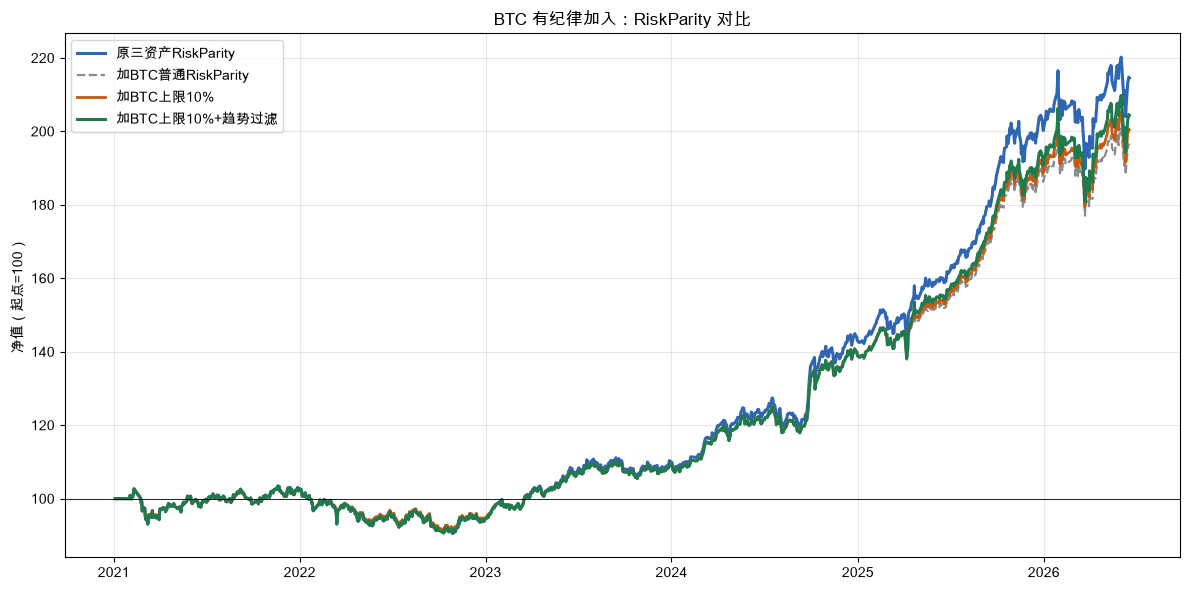

In [25]:
# Q3 风格：收益、波动、回撤、权重
q3_disciplined = pd.DataFrame({name: metric_row(result) for name, result in results_disciplined.items()}).T
print("Q3 视角：BTC 有纪律加入后的指标")
display(format_metric_table(q3_disciplined))
q3_disciplined.to_csv(OUTPUT_DIR / "disciplined_btc_q3_metrics.csv", encoding="utf-8-sig")

weights_disciplined = {name: result.weights_df().reindex(common_sessions).ffill().fillna(0) for name, result in results_disciplined.items()}
btc_weight_disciplined = pd.DataFrame({
    name: {
        "最新BTC权重": wdf[BTC_SYMBOL].iloc[-1] if BTC_SYMBOL in wdf.columns else 0.0,
        "平均BTC权重": wdf[BTC_SYMBOL].mean() if BTC_SYMBOL in wdf.columns else 0.0,
        "最高BTC权重": wdf[BTC_SYMBOL].max() if BTC_SYMBOL in wdf.columns else 0.0,
        "持有BTC天数占比": (wdf[BTC_SYMBOL] > 0).mean() if BTC_SYMBOL in wdf.columns else 0.0,
    }
    for name, wdf in weights_disciplined.items()
}).T
print("BTC 权重纪律检查")
display(btc_weight_disciplined.map(lambda x: f"{x:.2%}"))
btc_weight_disciplined.to_csv(OUTPUT_DIR / "disciplined_btc_weights.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(12, 6))
style_disciplined = {
    "原三资产RiskParity": {"color": "#2F66B3", "linestyle": "-", "linewidth": 2.2},
    "加BTC普通RiskParity": {"color": "#8A8A8A", "linestyle": "--", "linewidth": 1.6},
    "加BTC上限10%": {"color": "#C55A11", "linestyle": "-", "linewidth": 2.0},
    "加BTC上限10%+趋势过滤": {"color": "#1F7A4D", "linestyle": "-", "linewidth": 2.2},
}
for name, result in results_disciplined.items():
    eq = equity_series(result).reindex(common_sessions).dropna()
    norm = eq / eq.iloc[0] * 100
    ax.plot(norm.index, norm.values, label=name, **style_disciplined[name])
ax.axhline(100, color="black", linewidth=0.6)
ax.set_title("BTC 有纪律加入：RiskParity 对比")
ax.set_ylabel("净值（起点=100）")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "disciplined_btc_nav.png", dpi=150, bbox_inches="tight")
plt.show()

Q5 视角：BTC 有纪律加入后的完整指标


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,Alpha
原三资产RiskParity,114.53%,15.70%,11.81%,-12.44%,1.30,1.26,1.17,16.39%
加BTC普通RiskParity,96.28%,13.75%,10.66%,-11.49%,1.26,1.20,1.14,-1.86%
加BTC上限10%,100.44%,14.21%,10.82%,-11.54%,1.28,1.23,1.17,2.30%
加BTC上限10%+趋势过滤,104.37%,14.63%,11.40%,-12.39%,1.26,1.18,1.14,6.23%


逐年收益


,原三资产RiskParity,加BTC普通RiskParity,加BTC上限10%,加BTC上限10%+趋势过滤
2021,2.79%,2.53%,2.53%,2.71%
2022,-7.91%,-7.49%,-7.36%,-7.91%
2023,16.47%,15.25%,15.18%,15.60%
2024,30.22%,27.38%,27.63%,27.63%
2025,40.28%,34.54%,35.80%,37.42%
2026,5.25%,3.75%,4.59%,5.25%


月度收益结构


/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:132: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_end = s.groupby(s.index.to_period("M")).last()
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:135: UserWarning: Converting to Period representation will drop timezone information.
  baseline = pd.Series([first_val], index=[s.index[0].to_period("M") - 1])
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:132: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_end = s.groupby(s.index.to_period("M")).last()
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:135: UserWarning: Converting to Period representation will drop timezone information.
  baseline = pd.Series([first_val], index=[s.index[0].to_period("

,总月数,盈利月数,亏损月数,胜率,平均盈利月,平均亏损月,盈亏比,盈亏因子,中位数月收益,最好月,最差月,最长连赢,最长连亏
原三资产RiskParity,66.0,41.0,24.0,0.621212,0.029974,-0.017922,1.67,2.86,0.011808,0.108823,-0.070019,11.0,4.0
加BTC普通RiskParity,66.0,41.0,24.0,0.621212,0.026758,-0.016418,1.63,2.78,0.010727,0.100463,-0.065166,11.0,4.0
加BTC上限10%,66.0,41.0,24.0,0.621212,0.027359,-0.016526,1.66,2.83,0.010727,0.100462,-0.064775,11.0,4.0
加BTC上限10%+趋势过滤,66.0,41.0,24.0,0.621212,0.028504,-0.017549,1.62,2.77,0.010727,0.100461,-0.070019,11.0,4.0


回撤汇总


,最大回撤,平均回撤深度,平均恢复天数,最长恢复天数,回撤次数
原三资产RiskParity,-12.44%,-1.86%,16,251,64
加BTC普通RiskParity,-11.49%,-1.74%,17,253,60
加BTC上限10%,-11.54%,-1.73%,16,253,63
加BTC上限10%+趋势过滤,-12.39%,-1.80%,16,253,63


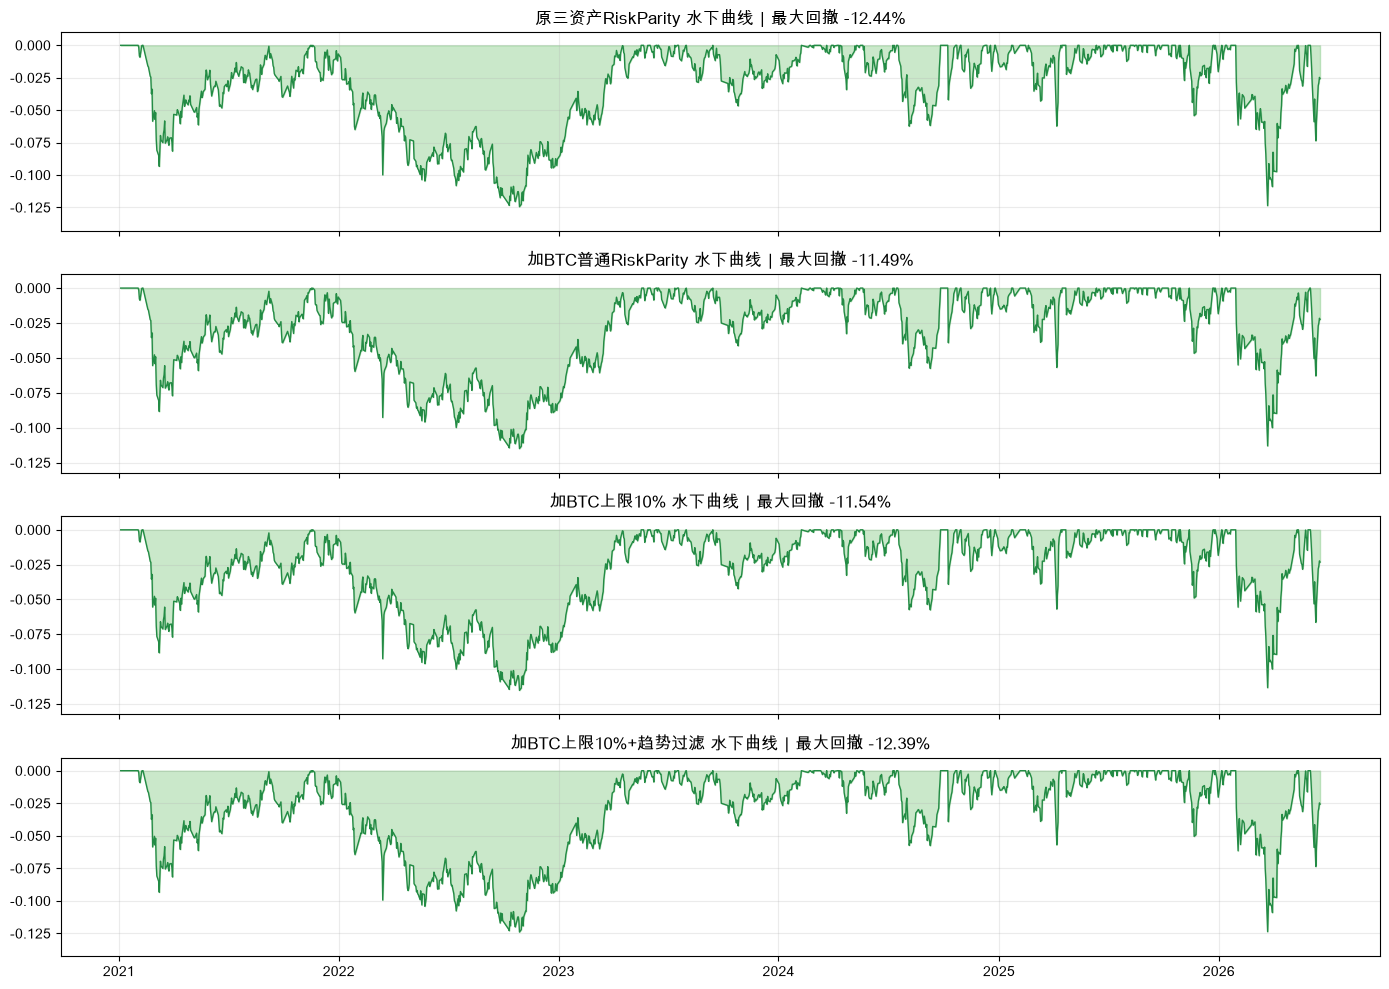

In [26]:
# Q5 风格：基准、Alpha、索提诺、逐年、月度、回撤
q5_disciplined = pd.DataFrame({name: metric_row_q5(result) for name, result in results_disciplined.items()}).T
q5_disciplined["Alpha"] = q5_disciplined["累计收益"] - q5_full.loc["三资产买入持有基准", "累计收益"]
print("Q5 视角：BTC 有纪律加入后的完整指标")
display(fmt_q5_table(q5_disciplined[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "索提诺", "Alpha"]]))
q5_disciplined.to_csv(OUTPUT_DIR / "disciplined_btc_q5_metrics.csv", encoding="utf-8-sig")

annual_disciplined = pd.DataFrame({name: annual_returns(result) for name, result in results_disciplined.items()})
print("逐年收益")
display(format_percent_table(annual_disciplined))
annual_disciplined.to_csv(OUTPUT_DIR / "disciplined_btc_annual_returns.csv", encoding="utf-8-sig")

monthly_disciplined = pd.DataFrame({name: monthly_stats(result) for name, result in results_disciplined.items()}).T
print("月度收益结构")
display(fmt_q5_table(monthly_disciplined[["总月数", "盈利月数", "亏损月数", "胜率", "平均盈利月", "平均亏损月", "盈亏比", "盈亏因子", "中位数月收益", "最好月", "最差月", "最长连赢", "最长连亏"]]))
monthly_disciplined.to_csv(OUTPUT_DIR / "disciplined_btc_monthly_stats.csv", encoding="utf-8-sig")

dd_disciplined = pd.DataFrame({name: drawdown_summary(result) for name, result in results_disciplined.items()}).T
print("回撤汇总")
display(dd_disciplined.assign(
    最大回撤=dd_disciplined["最大回撤"].map(lambda x: f"{x:.2%}"),
    平均回撤深度=dd_disciplined["平均回撤深度"].map(lambda x: f"{x:.2%}"),
    平均恢复天数=dd_disciplined["平均恢复天数"].map(lambda x: "—" if pd.isna(x) else f"{x:.0f}"),
    最长恢复天数=dd_disciplined["最长恢复天数"].map(lambda x: "—" if pd.isna(x) else f"{x:.0f}"),
    回撤次数=dd_disciplined["回撤次数"].astype(int),
))
dd_disciplined.to_csv(OUTPUT_DIR / "disciplined_btc_drawdown_summary.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (name, result) in zip(axes, results_disciplined.items()):
    dd = result.drawdown_series().sort_index()
    ax.fill_between(dd.index, dd.values, 0, color="#74C476", alpha=0.38)
    ax.plot(dd.index, dd.values, color="#238B45", linewidth=1)
    ax.set_title(f"{name} 水下曲线｜最大回撤 {dd.min():.2%}")
    ax.set_ylim(min(dd.min() * 1.15, -0.02), 0.01)
    ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "disciplined_btc_underwater.png", dpi=150, bbox_inches="tight")
plt.show()

BTC 权重上限与趋势过滤敏感性


累计收益    年化波动     最大回撤    夏普    卡玛   索提诺   BTC平均权重  BTC持有天数占比
BTC权重上限 趋势过滤                                                                 
0.05    关闭    106.92%  11.23%  -11.84%  1.30  1.26  1.18  0.048868   0.984848
        开启    108.33%  11.56%  -12.40%  1.27  1.21  1.15  0.026420   0.529545
0.10    关闭    100.44%  10.82%  -11.54%  1.28  1.23  1.17  0.080278   0.984848
        开启    104.37%  11.40%  -12.39%  1.26  1.18  1.14  0.044613   0.529545
0.15    关闭     96.73%  10.68%  -11.49%  1.27  1.20  1.15  0.089117   0.984848
        开启    103.48%  11.36%  -12.39%  1.25  1.17  1.14  0.049288   0.529545
0.20    关闭     96.28%  10.66%  -11.49%  1.26  1.20  1.14  0.090411   0.984848
        开启    103.48%  11.36%  -12.39%  1.25  1.17  1.14  0.049697   0.529545

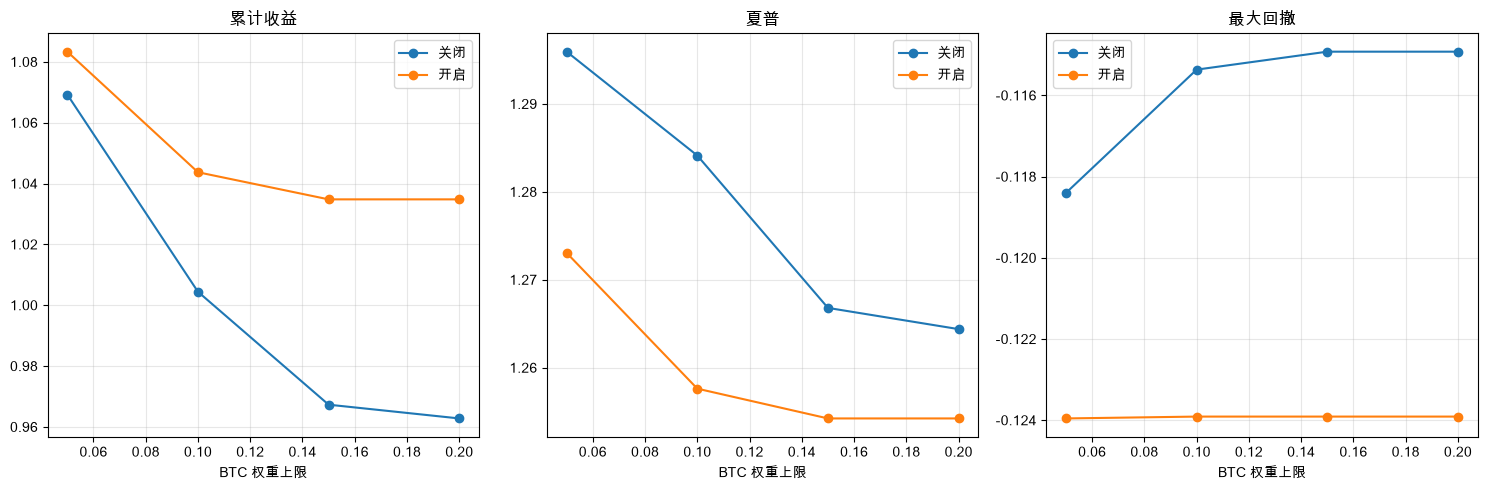

In [27]:
# 参数敏感性：趋势过滤 + 不同 BTC 权重上限
cap_values = [0.05, 0.10, 0.15, 0.20]
cap_rows = []
for cap in cap_values:
    for trend_on in [False, True]:
        optimizer = CappedRiskParityOptimizer(
            volatility_col="vol",
            caps={BTC_SYMBOL: cap},
            trend_symbol=BTC_SYMBOL if trend_on else None,
            trend_col=BTC_TREND_COL if trend_on else None,
        )
        result = run_custom_optimizer_strategy(
            f"cap-{cap:.0%}-{'trend' if trend_on else 'no-trend'}",
            optimizer,
        )
        wdf = result.weights_df().reindex(common_sessions).ffill().fillna(0)
        cap_rows.append({
            "BTC权重上限": cap,
            "趋势过滤": "开启" if trend_on else "关闭",
            "累计收益": result.total_return(),
            "年化波动": result.annualized_volatility(),
            "最大回撤": result.max_drawdown(),
            "夏普": result.sharpe_ratio(),
            "卡玛": result.calmar_ratio(),
            "索提诺": result.sortino_ratio(),
            "BTC平均权重": wdf[BTC_SYMBOL].mean() if BTC_SYMBOL in wdf.columns else 0.0,
            "BTC持有天数占比": (wdf[BTC_SYMBOL] > 0).mean() if BTC_SYMBOL in wdf.columns else 0.0,
        })
cap_sensitivity = pd.DataFrame(cap_rows)
print("BTC 权重上限与趋势过滤敏感性")
display(fmt_q5_table(cap_sensitivity.set_index(["BTC权重上限", "趋势过滤"])))
cap_sensitivity.to_csv(OUTPUT_DIR / "disciplined_btc_cap_trend_sensitivity.csv", encoding="utf-8-sig", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for trend_label, group in cap_sensitivity.groupby("趋势过滤"):
    axes[0].plot(group["BTC权重上限"], group["累计收益"], marker="o", label=trend_label)
    axes[1].plot(group["BTC权重上限"], group["夏普"], marker="o", label=trend_label)
    axes[2].plot(group["BTC权重上限"], group["最大回撤"], marker="o", label=trend_label)
axes[0].set_title("累计收益")
axes[1].set_title("夏普")
axes[2].set_title("最大回撤")
for ax in axes:
    ax.set_xlabel("BTC 权重上限")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "disciplined_btc_cap_trend_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
# 有纪律加入 BTC 的最终判断
base = q5_disciplined.loc["原三资产RiskParity"]
plain = q5_disciplined.loc["加BTC普通RiskParity"]
cap10 = q5_disciplined.loc["加BTC上限10%"]
trend = q5_disciplined.loc["加BTC上限10%+趋势过滤"]

best_total = q5_disciplined["累计收益"].idxmax()
best_sharpe = q5_disciplined["夏普"].idxmax()
best_calmar = q5_disciplined["卡玛"].idxmax()

print("有纪律加入 BTC：最终判断")
print("=" * 72)
print(f"原三资产 RiskParity：累计收益 {base['累计收益']:.2%}，夏普 {base['夏普']:.2f}，卡玛 {base['卡玛']:.2f}，最大回撤 {base['最大回撤']:.2%}。")
print(f"加 BTC 普通 RiskParity：累计收益 {plain['累计收益']:.2%}，夏普 {plain['夏普']:.2f}，卡玛 {plain['卡玛']:.2f}，最大回撤 {plain['最大回撤']:.2%}。")
print(f"加 BTC 上限 10%：累计收益 {cap10['累计收益']:.2%}，夏普 {cap10['夏普']:.2f}，卡玛 {cap10['卡玛']:.2f}，最大回撤 {cap10['最大回撤']:.2%}。")
print(f"加 BTC 上限 10% + 趋势过滤：累计收益 {trend['累计收益']:.2%}，夏普 {trend['夏普']:.2f}，卡玛 {trend['卡玛']:.2f}，最大回撤 {trend['最大回撤']:.2%}。")
print(f"\n收益最高：{best_total}；夏普最高：{best_sharpe}；卡玛最高：{best_calmar}。")
print(f"BTC 平均权重：普通 RP {btc_weight_disciplined.loc['加BTC普通RiskParity', '平均BTC权重']:.2%}，上限10% {btc_weight_disciplined.loc['加BTC上限10%', '平均BTC权重']:.2%}，趋势过滤 {btc_weight_disciplined.loc['加BTC上限10%+趋势过滤', '平均BTC权重']:.2%}。")
print(f"BTC 持有天数占比：趋势过滤版本 {btc_weight_disciplined.loc['加BTC上限10%+趋势过滤', '持有BTC天数占比']:.2%}。")

if trend['累计收益'] > plain['累计收益'] and trend['夏普'] >= plain['夏普']:
    print("\n通俗结论：趋势过滤确实比普通加入 BTC 更像一个有纪律的 BTC 策略。")
else:
    print("\n通俗结论：趋势过滤没有稳定打败普通 BTC RiskParity，说明这条规则还需要继续调参或换信号。")

if trend['累计收益'] > base['累计收益'] and trend['夏普'] >= base['夏普']:
    print("这次可以说：加 BTC 的纪律版本跑赢了原三资产 RiskParity。")
else:
    print("但如果和原三资产 RiskParity 比，它仍然没有成为更好的主方案；更适合作为进攻型备选。")

有纪律加入 BTC：最终判断
原三资产 RiskParity：累计收益 114.53%，夏普 1.30，卡玛 1.26，最大回撤 -12.44%。
加 BTC 普通 RiskParity：累计收益 96.28%，夏普 1.26，卡玛 1.20，最大回撤 -11.49%。
加 BTC 上限 10%：累计收益 100.44%，夏普 1.28，卡玛 1.23，最大回撤 -11.54%。
加 BTC 上限 10% + 趋势过滤：累计收益 104.37%，夏普 1.26，卡玛 1.18，最大回撤 -12.39%。

收益最高：原三资产RiskParity；夏普最高：原三资产RiskParity；卡玛最高：原三资产RiskParity。
BTC 平均权重：普通 RP 9.05%，上限10% 8.03%，趋势过滤 4.46%。
BTC 持有天数占比：趋势过滤版本 52.95%。

通俗结论：趋势过滤没有稳定打败普通 BTC RiskParity，说明这条规则还需要继续调参或换信号。
但如果和原三资产 RiskParity 比，它仍然没有成为更好的主方案；更适合作为进攻型备选。


---

## Q3/Q5 Practice: 标普500替换与纳指限仓

接下来测试三个更“未来可复现”一点的版本：

1. **沪深300 + 标普500 + 黄金**：用更宽的美股核心替代纳指100。
2. **沪深300 + 纳指100 + 黄金，但限制纳指最高权重 15%**：保留成长暴露，但别让它过度影响组合。
3. **沪深300 + 标普500 + 黄金 + 小仓位纳指100**：标普500做美股核心，纳指100只做卫星仓位，最高 10%。

仍然使用 20 日波动率 RiskParity、10 日再平衡，并按 Q3/Q5 的同一套指标评估。

In [29]:
# 标普500替换与纳指限仓组合
SP500_SYMBOL = "513500.SS"
SYMBOL_NAMES_EXTENDED = {
    **SYMBOL_NAMES_WITH_BTC,
    SP500_SYMBOL: "标普500ETF",
}

for sym in (SP500_SYMBOL,):
    downloader.download(sym, start=START, end=today)

raw_mktdata[SP500_SYMBOL] = raw_market.get_bars(SP500_SYMBOL, START, today).copy()
normalized_data[SP500_SYMBOL] = normalize_to_session_index(raw_mktdata[SP500_SYMBOL])

candidate_symbols = tuple(sorted(set(SYMBOLS + (SP500_SYMBOL,))))
candidate_sessions = base_sessions
for sym in candidate_symbols:
    df = normalized_data[sym].copy()
    df = df.reindex(candidate_sessions).dropna(subset=["close"])
    candidate_sessions = candidate_sessions.intersection(df.index)
candidate_sessions = candidate_sessions.sort_values()

candidate_data = {}
for sym in candidate_symbols:
    df = normalized_data[sym].reindex(candidate_sessions).copy()
    df.attrs["currency"] = "USD"
    df.attrs["timezone"] = "Asia/Shanghai"
    candidate_data[sym] = df

candidate_market = InMemoryMarketDataProvider(candidate_data)
print(f"候选组合共同交易日：{len(candidate_sessions)} 天，{candidate_sessions[0].date()} 到 {candidate_sessions[-1].date()}")
for sym in candidate_symbols:
    close = candidate_data[sym]["close"]
    print(f"  {SYMBOL_NAMES_EXTENDED.get(sym, sym)}: {close.iloc[-1] / close.iloc[0] - 1:.2%}")

候选组合共同交易日：1320 天，2021-01-04 到 2026-06-18
  沪深300ETF: 4.65%
  纳指100ETF: 161.48%
  标普500ETF: 124.91%
  黄金ETF: 128.29%


In [30]:
# 用 RiskParity + 权重上限实现三个候选组合
class CappedRiskParityBySymbolOptimizer:
    name = "CappedRiskParityBySymbol"

    def __init__(self, volatility_col, caps=None):
        self.volatility_col = volatility_col
        self.caps = caps or {}

    def optimize(self, signals, indicators):
        inv_vols = {}
        for symbol, df in indicators.items():
            if self.volatility_col not in df.columns:
                continue
            vol = float(df[self.volatility_col].iloc[-1])
            if pd.isna(vol) or vol <= 0:
                continue
            inv_vols[symbol] = 1.0 / vol
        if not inv_vols:
            return {"CASH": 1.0}

        weights = {symbol: inv / sum(inv_vols.values()) for symbol, inv in inv_vols.items()}

        fixed = {}
        free = set(weights)
        changed = True
        while changed:
            changed = False
            remaining = 1.0 - sum(fixed.values())
            free_total = sum(weights[s] for s in free)
            proposed = {s: remaining * weights[s] / free_total for s in free} if free_total > 0 else {}
            for symbol, weight in list(proposed.items()):
                cap = self.caps.get(symbol)
                if cap is not None and weight > cap:
                    fixed[symbol] = cap
                    free.remove(symbol)
                    changed = True
        remaining = 1.0 - sum(fixed.values())
        free_total = sum(weights[s] for s in free)
        result = dict(fixed)
        for symbol in free:
            result[symbol] = remaining * weights[symbol] / free_total if free_total > 0 else 0.0
        cash = 1.0 - sum(result.values())
        if cash > 1e-9:
            result["CASH"] = cash
        return result


def run_candidate_strategy(name, symbols, optimizer):
    signal = Threshold()
    signal.required_indicators = {"vol": (RollingVolatility(), {"column": "close", "period": 20})}
    strategy = Strategy(
        name=name,
        universe=StaticUniverse(symbols=symbols, name=name),
        signals={"active": (signal, {"column": "close", "threshold": 0, "relationship": "gt"})},
        portfolio=optimizer,
    )
    data = {sym: candidate_data[sym] for sym in symbols}
    return Engine().run(
        strategy,
        market=InMemoryMarketDataProvider(data),
        broker=SimBroker(),
        start=START,
        end=today,
        rules=[RebalanceFrequencyRule(interval_days=10)],
    )

symbols_sp500_core = ("510300.SS", SP500_SYMBOL, "518880.SS")
symbols_nasdaq_cap = SYMBOLS
symbols_sp500_plus_nasdaq = ("510300.SS", SP500_SYMBOL, "518880.SS", "513100.SS")

result_sp500_core = run_candidate_strategy(
    "沪深300+标普500+黄金 RP",
    symbols_sp500_core,
    RiskParityOptimizer(volatility_col="vol"),
)
result_nasdaq_cap15 = run_candidate_strategy(
    "沪深300+纳指100限15%+黄金 RP",
    symbols_nasdaq_cap,
    CappedRiskParityBySymbolOptimizer(volatility_col="vol", caps={"513100.SS": 0.15}),
)
result_sp500_plus_nasdaq_cap10 = run_candidate_strategy(
    "沪深300+标普500+黄金+纳指10% RP",
    symbols_sp500_plus_nasdaq,
    CappedRiskParityBySymbolOptimizer(volatility_col="vol", caps={"513100.SS": 0.10}),
)

results_candidates = {
    "原三资产RP": result_rp3_aligned,
    "标普500替换RP": result_sp500_core,
    "纳指限15% RP": result_nasdaq_cap15,
    "标普500+纳指10% RP": result_sp500_plus_nasdaq_cap10,
}
print("候选组合运行完成")

候选组合运行完成


In [31]:
# Q3/Q5 指标、权重、年度收益、月度结构
candidate_q5 = pd.DataFrame({name: metric_row_q5(result) for name, result in results_candidates.items()}).T
candidate_q5["Alpha"] = candidate_q5["累计收益"] - q5_full.loc["三资产买入持有基准", "累计收益"]
print("候选组合 Q5 指标")
display(fmt_q5_table(candidate_q5[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "索提诺", "Alpha"]]))
candidate_q5.to_csv(OUTPUT_DIR / "candidate_sp500_nasdaq_q5_metrics.csv", encoding="utf-8-sig")

weights_candidates = {}
for name, result in results_candidates.items():
    wdf = result.weights_df().reindex(candidate_sessions).ffill().fillna(0)
    weights_candidates[name] = {SYMBOL_NAMES_EXTENDED.get(sym, sym): (wdf[sym].mean() if sym in wdf.columns else 0.0) for sym in candidate_symbols}
weights_candidates_df = pd.DataFrame(weights_candidates).T.fillna(0)
print("候选组合平均权重")
display(weights_candidates_df.map(lambda x: f"{x:.2%}"))
weights_candidates_df.to_csv(OUTPUT_DIR / "candidate_sp500_nasdaq_weights.csv", encoding="utf-8-sig")

annual_candidates = pd.DataFrame({name: annual_returns(result) for name, result in results_candidates.items()})
print("候选组合逐年收益")
display(format_percent_table(annual_candidates))
annual_candidates.to_csv(OUTPUT_DIR / "candidate_sp500_nasdaq_annual_returns.csv", encoding="utf-8-sig")

monthly_candidates = pd.DataFrame({name: monthly_stats(result) for name, result in results_candidates.items()}).T
print("候选组合月度收益结构")
display(fmt_q5_table(monthly_candidates[["总月数", "盈利月数", "亏损月数", "胜率", "平均盈利月", "平均亏损月", "盈亏比", "盈亏因子", "最好月", "最差月"]]))
monthly_candidates.to_csv(OUTPUT_DIR / "candidate_sp500_nasdaq_monthly_stats.csv", encoding="utf-8-sig")

候选组合 Q5 指标


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,Alpha
原三资产RP,114.53%,15.70%,11.81%,-12.44%,1.30,1.26,1.17,16.39%
标普500替换RP,99.21%,14.07%,10.87%,-11.97%,1.27,1.18,1.13,1.07%
纳指限15% RP,94.23%,13.52%,11.72%,-14.15%,1.14,0.96,1.02,-3.92%
标普500+纳指10% RP,106.43%,14.85%,11.33%,-11.91%,1.28,1.25,1.15,8.29%


候选组合平均权重


,沪深300ETF,纳指100ETF,标普500ETF,黄金ETF
原三资产RP,32.75%,25.44%,0.00%,40.30%
标普500替换RP,30.47%,0.00%,30.58%,37.44%
纳指限15% RP,37.93%,14.69%,0.00%,45.86%
标普500+纳指10% RP,27.42%,9.85%,27.52%,33.70%


候选组合逐年收益


,原三资产RP,标普500替换RP,纳指限15% RP,标普500+纳指10% RP
2021,2.79%,5.19%,-1.18%,7.04%
2022,-7.91%,-6.02%,-6.64%,-8.05%
2023,16.47%,12.36%,11.20%,15.81%
2024,30.22%,28.51%,24.86%,29.35%
2025,40.28%,35.26%,43.93%,33.38%
2026,5.25%,2.06%,4.43%,3.56%


候选组合月度收益结构


/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:132: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_end = s.groupby(s.index.to_period("M")).last()
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:135: UserWarning: Converting to Period representation will drop timezone information.
  baseline = pd.Series([first_val], index=[s.index[0].to_period("M") - 1])
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:132: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  month_end = s.groupby(s.index.to_period("M")).last()
/Users/zz/Desktop/Code/zsd/xquant/.venv/lib/python3.12/site-packages/oxq/portfolio/analytics.py:135: UserWarning: Converting to Period representation will drop timezone information.
  baseline = pd.Series([first_val], index=[s.index[0].to_period("

,总月数,盈利月数,亏损月数,胜率,平均盈利月,平均亏损月,盈亏比,盈亏因子,最好月,最差月
原三资产RP,66.0,41.0,24.0,0.621212,0.029974,-0.017922,1.67,2.86,0.108823,-0.070019
标普500替换RP,66.0,39.0,26.0,0.590909,0.027488,-0.013625,2.02,3.03,0.095049,-0.076165
纳指限15% RP,66.0,39.0,26.0,0.590909,0.029494,-0.017395,1.70,2.54,0.109420,-0.067111
标普500+纳指10% RP,66.0,44.0,21.0,0.666667,0.025663,-0.017822,1.44,3.02,0.085208,-0.076446


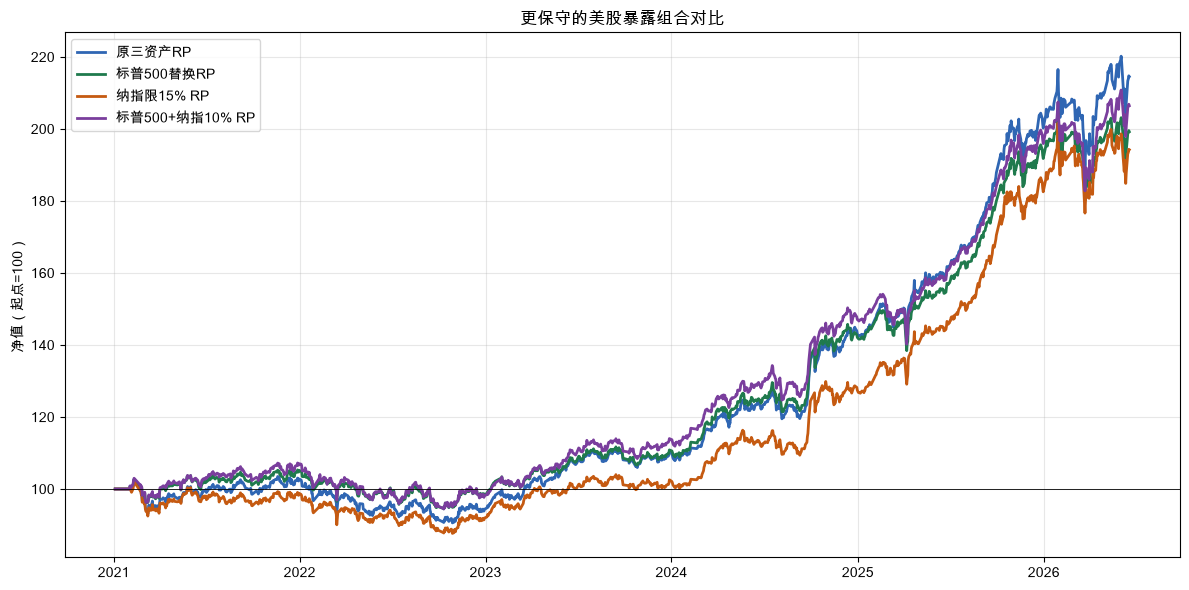

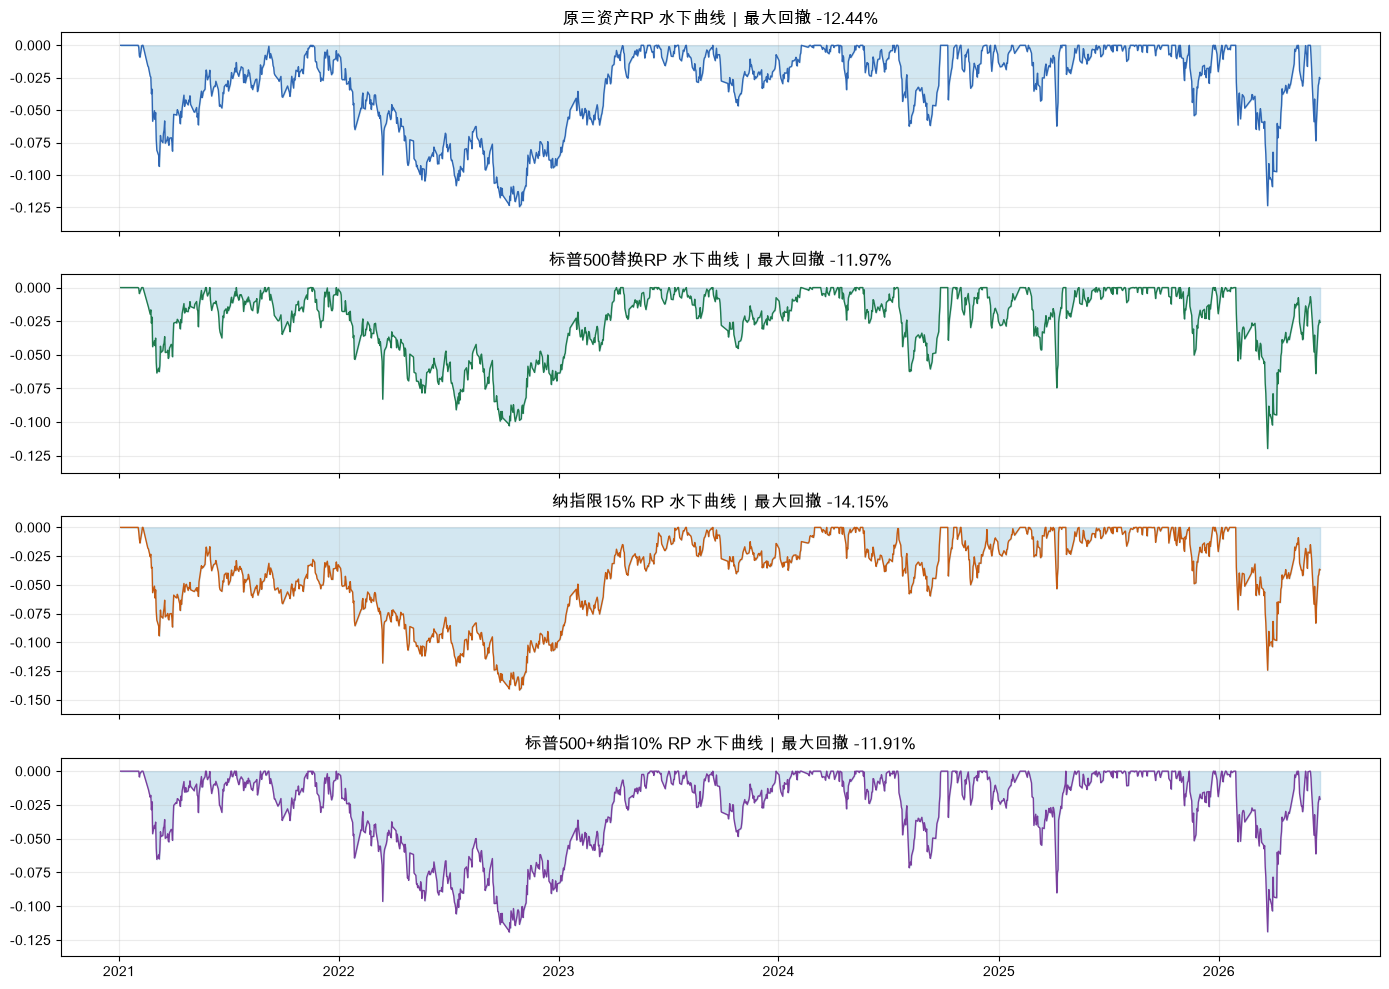

In [32]:
# 候选组合净值和水下曲线
fig, ax = plt.subplots(figsize=(12, 6))
colors = {
    "原三资产RP": "#2F66B3",
    "标普500替换RP": "#1F7A4D",
    "纳指限15% RP": "#C55A11",
    "标普500+纳指10% RP": "#7A3E9D",
}
for name, result in results_candidates.items():
    eq = equity_series(result).reindex(candidate_sessions).dropna()
    norm = eq / eq.iloc[0] * 100
    ax.plot(norm.index, norm.values, label=name, color=colors[name], linewidth=2)
ax.axhline(100, color="black", linewidth=0.6)
ax.set_title("更保守的美股暴露组合对比")
ax.set_ylabel("净值（起点=100）")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "candidate_sp500_nasdaq_nav.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (name, result) in zip(axes, results_candidates.items()):
    dd = result.drawdown_series().sort_index()
    ax.fill_between(dd.index, dd.values, 0, color="#9ECAE1", alpha=0.45)
    ax.plot(dd.index, dd.values, color=colors[name], linewidth=1)
    ax.set_title(f"{name} 水下曲线｜最大回撤 {dd.min():.2%}")
    ax.set_ylim(min(dd.min() * 1.15, -0.02), 0.01)
    ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "candidate_sp500_nasdaq_underwater.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
# 候选组合总结
best_total = candidate_q5["累计收益"].idxmax()
best_sharpe = candidate_q5["夏普"].idxmax()
best_calmar = candidate_q5["卡玛"].idxmax()
print("标普500替换与纳指限仓：总结")
print("=" * 72)
for name, row in candidate_q5.iterrows():
    print(f"{name}: 累计收益 {row['累计收益']:.2%}，夏普 {row['夏普']:.2f}，卡玛 {row['卡玛']:.2f}，最大回撤 {row['最大回撤']:.2%}。")
print(f"\n收益最高：{best_total}；夏普最高：{best_sharpe}；卡玛最高：{best_calmar}。")
print("\n通俗判断：")
print("标普500替换版更温和，但这段样本里收益低于纳指100版。")
print("限制纳指权重能降低对科技成长股的依赖，但也会明显放弃这段样本里的强收益来源。")
print("标普500做核心、纳指做小仓位卫星，是更分散的结构；如果它的风险调整指标接近原组合，未来可复现性会比纯纳指100版更让人安心。")

标普500替换与纳指限仓：总结
原三资产RP: 累计收益 114.53%，夏普 1.30，卡玛 1.26，最大回撤 -12.44%。
标普500替换RP: 累计收益 99.21%，夏普 1.27，卡玛 1.18，最大回撤 -11.97%。
纳指限15% RP: 累计收益 94.23%，夏普 1.14，卡玛 0.96，最大回撤 -14.15%。
标普500+纳指10% RP: 累计收益 106.43%，夏普 1.28，卡玛 1.25，最大回撤 -11.91%。

收益最高：原三资产RP；夏普最高：原三资产RP；卡玛最高：原三资产RP。

通俗判断：
标普500替换版更温和，但这段样本里收益低于纳指100版。
限制纳指权重能降低对科技成长股的依赖，但也会明显放弃这段样本里的强收益来源。
标普500做核心、纳指做小仓位卫星，是更分散的结构；如果它的风险调整指标接近原组合，未来可复现性会比纯纳指100版更让人安心。


---

## Q3/Q5 Practice: 十年样本复核

前面的回测从 2021 年开始，确实容易赶上纳指100和黄金都表现很好的阶段。这里把起点往前推到 **2016-06-21**，也就是从当前日期 2026-06-21 往前约十年，复核同样几个组合：

1. 原三资产 RiskParity：沪深300 + 纳指100 + 黄金
2. 标普500替换：沪深300 + 标普500 + 黄金
3. 纳指限15%：沪深300 + 纳指100最高15% + 黄金
4. 标普500核心 + 纳指10%卫星：沪深300 + 标普500 + 黄金 + 纳指100最高10%

In [34]:
# 十年样本数据准备
START_10Y = "2016-06-21"
TEN_YEAR_SYMBOLS = ("510300.SS", "513100.SS", SP500_SYMBOL, "518880.SS")

for sym in TEN_YEAR_SYMBOLS:
    downloader.download(sym, start=START_10Y, end=today)

market_10y_raw = LocalMarketDataProvider(currency="USD")
raw_10y = {sym: market_10y_raw.get_bars(sym, START_10Y, today).copy() for sym in TEN_YEAR_SYMBOLS}
normalized_10y = {sym: normalize_to_session_index(df) for sym, df in raw_10y.items()}

sessions_10y = normalized_10y[TEN_YEAR_SYMBOLS[0]].index
for sym in TEN_YEAR_SYMBOLS[1:]:
    sessions_10y = sessions_10y.intersection(normalized_10y[sym].index)
sessions_10y = sessions_10y.sort_values()

data_10y = {}
for sym in TEN_YEAR_SYMBOLS:
    df = normalized_10y[sym].reindex(sessions_10y).copy()
    df.attrs["currency"] = "USD"
    df.attrs["timezone"] = "Asia/Shanghai"
    data_10y[sym] = df

market_10y = InMemoryMarketDataProvider(data_10y)
print(f"十年共同交易日：{len(sessions_10y)} 天，{sessions_10y[0].date()} 到 {sessions_10y[-1].date()}")
for sym in TEN_YEAR_SYMBOLS:
    close = data_10y[sym]["close"]
    print(f"  {SYMBOL_NAMES_EXTENDED.get(sym, sym)}: {close.iloc[-1] / close.iloc[0] - 1:.2%}")

十年共同交易日：2424 天，2016-06-21 到 2026-06-18
  沪深300ETF: 90.76%
  纳指100ETF: 632.86%
  标普500ETF: 302.20%
  黄金ETF: 228.47%


In [35]:
# 十年样本：运行候选组合

def run_candidate_strategy_10y(name, symbols, optimizer):
    signal = Threshold()
    signal.required_indicators = {"vol": (RollingVolatility(), {"column": "close", "period": 20})}
    strategy = Strategy(
        name=name,
        universe=StaticUniverse(symbols=symbols, name=name),
        signals={"active": (signal, {"column": "close", "threshold": 0, "relationship": "gt"})},
        portfolio=optimizer,
    )
    data = {sym: data_10y[sym] for sym in symbols}
    return Engine().run(
        strategy,
        market=InMemoryMarketDataProvider(data),
        broker=SimBroker(),
        start=START_10Y,
        end=today,
        rules=[RebalanceFrequencyRule(interval_days=10)],
    )

results_10y_candidates = {
    "原三资产RP": run_candidate_strategy_10y(
        "10y-original-rp",
        ("510300.SS", "513100.SS", "518880.SS"),
        RiskParityOptimizer(volatility_col="vol"),
    ),
    "标普500替换RP": run_candidate_strategy_10y(
        "10y-sp500-rp",
        ("510300.SS", SP500_SYMBOL, "518880.SS"),
        RiskParityOptimizer(volatility_col="vol"),
    ),
    "纳指限15% RP": run_candidate_strategy_10y(
        "10y-nasdaq-cap15-rp",
        ("510300.SS", "513100.SS", "518880.SS"),
        CappedRiskParityBySymbolOptimizer(volatility_col="vol", caps={"513100.SS": 0.15}),
    ),
    "标普500+纳指10% RP": run_candidate_strategy_10y(
        "10y-sp500-nasdaq10-rp",
        ("510300.SS", SP500_SYMBOL, "518880.SS", "513100.SS"),
        CappedRiskParityBySymbolOptimizer(volatility_col="vol", caps={"513100.SS": 0.10}),
    ),
}
print("十年候选组合运行完成")

十年候选组合运行完成


In [36]:
# 十年样本：Q3/Q5 指标、权重、年度收益
metrics_10y = pd.DataFrame({name: metric_row_q5(result) for name, result in results_10y_candidates.items()}).T
print("十年样本 Q5 指标")
display(fmt_q5_table(metrics_10y[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "索提诺"]]))
metrics_10y.to_csv(OUTPUT_DIR / "ten_year_candidate_q5_metrics.csv", encoding="utf-8-sig")

weights_10y = {}
for name, result in results_10y_candidates.items():
    wdf = result.weights_df().reindex(sessions_10y).ffill().fillna(0)
    weights_10y[name] = {SYMBOL_NAMES_EXTENDED.get(sym, sym): (wdf[sym].mean() if sym in wdf.columns else 0.0) for sym in TEN_YEAR_SYMBOLS}
weights_10y_df = pd.DataFrame(weights_10y).T.fillna(0)
print("十年样本平均权重")
display(weights_10y_df.map(lambda x: f"{x:.2%}"))
weights_10y_df.to_csv(OUTPUT_DIR / "ten_year_candidate_weights.csv", encoding="utf-8-sig")

annual_10y = pd.DataFrame({name: annual_returns(result) for name, result in results_10y_candidates.items()})
print("十年样本逐年收益")
display(format_percent_table(annual_10y))
annual_10y.to_csv(OUTPUT_DIR / "ten_year_candidate_annual_returns.csv", encoding="utf-8-sig")

十年样本 Q5 指标


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺
原三资产RP,314.17%,15.93%,11.23%,-13.79%,1.38,1.15,1.23
标普500替换RP,230.60%,13.24%,10.49%,-16.06%,1.24,0.82,1.09
纳指限15% RP,220.25%,12.87%,10.98%,-14.90%,1.16,0.86,1.02
标普500+纳指10% RP,260.13%,14.25%,10.99%,-16.85%,1.27,0.85,1.11


十年样本平均权重


,沪深300ETF,纳指100ETF,标普500ETF,黄金ETF
原三资产RP,31.08%,25.88%,0.00%,42.21%
标普500替换RP,29.24%,0.00%,30.33%,39.60%
纳指限15% RP,36.23%,14.79%,0.00%,48.16%
标普500+纳指10% RP,26.32%,9.91%,27.30%,35.65%


十年样本逐年收益


,原三资产RP,标普500替换RP,纳指限15% RP,标普500+纳指10% RP
2016,1.30%,3.50%,-0.71%,4.28%
2017,16.25%,14.43%,14.44%,15.37%
2018,-2.64%,-4.06%,-3.10%,-3.43%
2019,31.12%,28.85%,28.40%,30.24%
2020,27.43%,14.92%,19.81%,17.06%
2021,3.07%,4.72%,-0.84%,6.57%
2022,-8.01%,-5.66%,-7.09%,-7.76%
2023,18.23%,13.96%,11.93%,17.29%
2024,28.36%,25.88%,21.39%,26.88%
2025,37.89%,32.86%,40.54%,31.17%


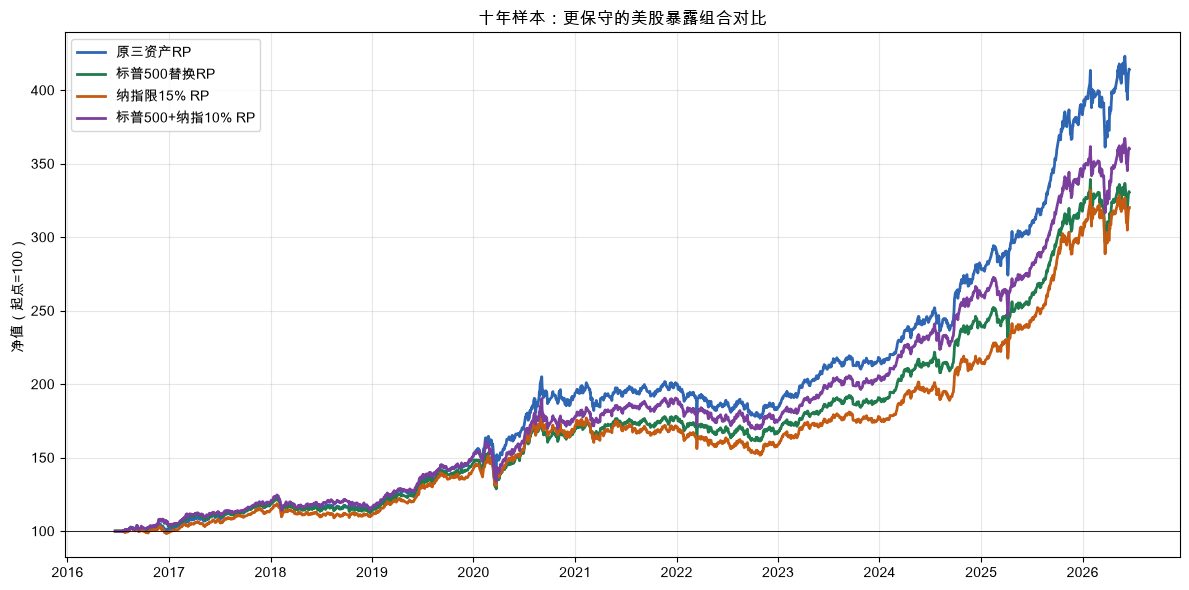

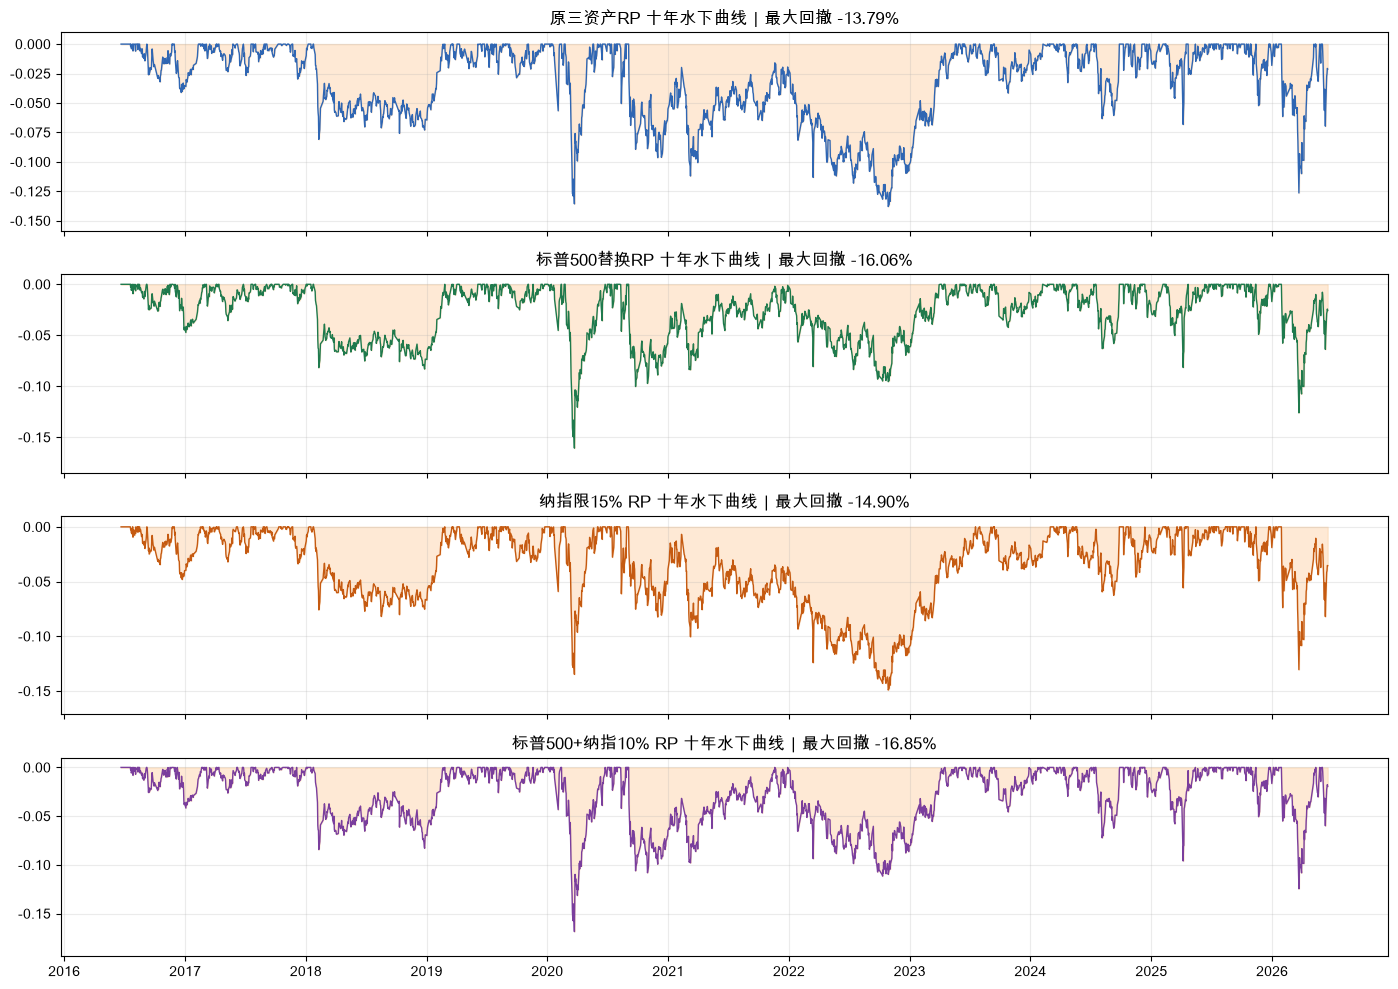

In [37]:
# 十年样本：净值曲线和水下曲线
fig, ax = plt.subplots(figsize=(12, 6))
for name, result in results_10y_candidates.items():
    eq = equity_series(result).reindex(sessions_10y).dropna()
    norm = eq / eq.iloc[0] * 100
    ax.plot(norm.index, norm.values, label=name, color=colors[name], linewidth=2)
ax.axhline(100, color="black", linewidth=0.6)
ax.set_title("十年样本：更保守的美股暴露组合对比")
ax.set_ylabel("净值（起点=100）")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ten_year_candidate_nav.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (name, result) in zip(axes, results_10y_candidates.items()):
    dd = result.drawdown_series().sort_index()
    ax.fill_between(dd.index, dd.values, 0, color="#FDD0A2", alpha=0.45)
    ax.plot(dd.index, dd.values, color=colors[name], linewidth=1)
    ax.set_title(f"{name} 十年水下曲线｜最大回撤 {dd.min():.2%}")
    ax.set_ylim(min(dd.min() * 1.15, -0.02), 0.01)
    ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ten_year_candidate_underwater.png", dpi=150, bbox_inches="tight")
plt.show()

In [38]:
# 十年样本总结
best_total_10y = metrics_10y["累计收益"].idxmax()
best_sharpe_10y = metrics_10y["夏普"].idxmax()
best_calmar_10y = metrics_10y["卡玛"].idxmax()
print("十年样本总结")
print("=" * 72)
for name, row in metrics_10y.iterrows():
    print(f"{name}: 累计收益 {row['累计收益']:.2%}，年化 {row['年化收益']:.2%}，夏普 {row['夏普']:.2f}，卡玛 {row['卡玛']:.2f}，最大回撤 {row['最大回撤']:.2%}。")
print(f"\n十年收益最高：{best_total_10y}；夏普最高：{best_sharpe_10y}；卡玛最高：{best_calmar_10y}。")
print("\n通俗判断：")
print("把样本拉长到十年后，原三资产 RP 仍然是历史最优；这说明它不只是 2021 年以后才好。")
print("但这也进一步说明：过去十年纳指100确实非常强，原组合的优势高度依赖这段美股科技成长风格胜出。")
print("标普500+纳指10% 仍然是结构更均衡的备选，但在十年历史里没有追上原三资产 RP。")

十年样本总结
原三资产RP: 累计收益 314.17%，年化 15.93%，夏普 1.38，卡玛 1.15，最大回撤 -13.79%。
标普500替换RP: 累计收益 230.60%，年化 13.24%，夏普 1.24，卡玛 0.82，最大回撤 -16.06%。
纳指限15% RP: 累计收益 220.25%，年化 12.87%，夏普 1.16，卡玛 0.86，最大回撤 -14.90%。
标普500+纳指10% RP: 累计收益 260.13%，年化 14.25%，夏普 1.27，卡玛 0.85，最大回撤 -16.85%。

十年收益最高：原三资产RP；夏普最高：原三资产RP；卡玛最高：原三资产RP。

通俗判断：
把样本拉长到十年后，原三资产 RP 仍然是历史最优；这说明它不只是 2021 年以后才好。
但这也进一步说明：过去十年纳指100确实非常强，原组合的优势高度依赖这段美股科技成长风格胜出。
标普500+纳指10% 仍然是结构更均衡的备选，但在十年历史里没有追上原三资产 RP。
